# Pemetaan Penggunaan dan Tutupan Lahan (LULC) Jawa Timur

## Business Understanding

### Latar Belakang

Permukaan Bumi memiliki beragam jenis tutupan lahan yang mencerminkan kondisi lingkungan dan aktivitas manusia. Provinsi Jawa Timur memiliki wilayah pertanian, permukiman, hutan, mangrove, serta perairan yang tersebar di berbagai daerah. Keberagaman tersebut menjadikan pemetaan tutupan lahan (*Land Use and Land Cover* / LULC) penting untuk memahami kondisi wilayah dan mendukung perencanaan tata ruang serta kebijakan pengelolaan lingkungan.

Melalui citra satelit **Sentinel-2 Level-2A**, berbagai objek permukaan Bumi dapat dikenali berdasarkan karakteristik pantulan spektralnya. Dengan memanfaatkan Sistem Informasi Geografis (SIG) dan algoritma *Machine Learning*, khususnya **Random Forest**, proses klasifikasi dapat dilakukan secara sistematis untuk membedakan enam kelas tutupan lahan, yaitu **Sawah, Bangunan, Hutan (Lahan Hijau), Mangrove, Laut (Perairan Terbuka), dan Danau (Ranu)**.

### Tujuan Analisis

1. **Melakukan Klasifikasi Tutupan Lahan:** Mengidentifikasi enam kelas tutupan lahan di wilayah Jawa Timur berdasarkan fitur spektral Sentinel-2 menggunakan algoritma *Machine Learning*, serta mengevaluasi hasil klasifikasi melalui data *training*, *testing*, dan metrik akurasi.

2. **Menyajikan Informasi Spasial:** Memvisualisasikan hasil klasifikasi dalam bentuk peta interaktif menggunakan **Folium/Leaflet** dengan latar citra satelit, serta mengembangkan aplikasi berbasis **Streamlit** dan dokumentasi melalui **Jupyter Book**.

Hasil analisis ini diharapkan dapat memberikan gambaran mengenai persebaran tutupan lahan pada wilayah yang diteliti serta menjadi informasi pendukung dalam memahami pemanfaatan ruang, pengelolaan lingkungan, dan perencanaan kebijakan tata ruang di Jawa Timur.

## Data Understanding
### Deskripsi Dataset dan Label Kelas

Eksperimen ini menggunakan total 300 data titik sampel koordinat. Penentuan kelas Klasifikasi Penutup Lahan yang telah disesuaikan dengan lanskap Jawa Timur:

| Label | Kelas | Deskripsi |
|---:|---|---|
| 1 | **Sawah** | Area pertanian yang digunakan untuk budidaya padi. |
| 2 | **Bangunan** | Kawasan terbangun seperti permukiman, gedung, jalan, dan fasilitas lainnya. |
| 3 | **Hutan** | Wilayah dengan vegetasi rapat seperti hutan dan kawasan hijau dengan tutupan pohon dominan. |
| 4 | **Mangrove** | Vegetasi mangrove yang berada di kawasan pesisir dan daerah pasang surut. |
| 5 | **Danau** | Badan air tawar seperti danau, waduk, telaga, atau bendungan. |
| 6 | **Laut** | Perairan laut terbuka yang berada di wilayah pesisir Jawa Timur. |

### Ekstraksi Fitur

**Band Spektral Sentinel-2A:**
Citra satelit bersumber dari sensor **Multispectral Instrument (MSI)** pada wahana **Sentinel-2A Level-2A** (*Copernicus Data Space Ecosystem* - CDSE) dengan koreksi atmosfer *Bottom-of-Atmosphere* (BOA):

* **B02 (Blue - 490 nm)**: Resolusi 10 meter. Berguna untuk mendeteksi badan air jernih dan hamburan partikel atmosfer.
* **B03 (Green - 560 nm)**: Resolusi 10 meter. Puncak pantulan klorofil daun pada spektrum tampak dan deteksi sedimen perairan.
* **B04 (Red - 665 nm)**: Resolusi 10 meter. Pita serapan utama klorofil; pembeda tajam antara vegetasi hidup dan material tanah terbuka/bangunan.
* **B08 (Near Infrared / NIR - 842 nm)**: Resolusi 10 meter. Pantulan sangat tinggi dari struktur sel mesofil daun; diserap hampir total oleh air jernih.
* **B11 (Short-Wave Infrared / SWIR - 1610 nm)**: Resolusi 20 meter (di-resample ke 10 m). Sensitif terhadap kelembapan air pada tanah dan vegetasi, serta reflektansi material atap/beton.

**Indeks Transformasi (Rumus Spektral):**

Untuk mempermudah algoritma dalam mengenali pola, fitur spektral dasar dikalkulasikan ke dalam dua metrik indeks matematis:

1. **NDVI (*Normalized Difference Vegetation Index*)**
   Mengukur tingkat kehijauan, kerapatan, dan kesehatan vegetasi.
   > **Rumus:** 
   
   $$NDVI = \frac{B08 - B04}{B08 + B04}$$

2. **NDWI (*Normalized Difference Water Index*)**
   Mendeteksi fitur kebasahan dan badan air secara tegas, sembari meminimalisir efek pantulan dari tanah maupun vegetasi terrestrial.
   > **Rumus:** 
   
   $$NDWI = \frac{B03 - B08}{B03 + B08}$$

## Data Collection

### Import Library

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
import openeo
import folium
import matplotlib.pyplot as plt
import joblib

from shapely.validation import make_valid
from rasterio.mask import mask as rio_mask
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

### Membaca Polygon Ground Truth

Data ground truth dari enam kelas tutupan lahan dibaca, diberi label, lalu digabungkan menjadi satu GeoDataFrame.

In [2]:
RAW = Path('data/raw')
PROCESSED = Path('data/processed')
HASIL = Path('hasil')
HASIL.mkdir(exist_ok=True)

SUMBER = {
    'Sawah': RAW / 'sawah.zip',
    'Bangunan': RAW / 'bangunan.zip',
    'Hutan': RAW / 'hutan.zip',
    'Mangrove': RAW / 'mangrove.zip',
    'Danau': RAW / 'danau.zip',
    'Laut': RAW / 'laut.zip'
}

LABEL = {
    'Sawah': 1,
    'Bangunan': 2,
    'Hutan': 3,
    'Mangrove': 4,
    'Danau': 5,
    'Laut': 6
}

bagian = []

for kelas, file in SUMBER.items():
    g = gpd.read_file(f'zip://{file.as_posix()}').to_crs('EPSG:4326')
    g = g[g.geometry.notna() & ~g.geometry.is_empty].copy()
    g['geometry'] = g.geometry.apply(lambda x: x if x.is_valid else make_valid(x))
    g['label_teks'] = kelas
    g['label'] = LABEL[kelas]
    g['poligon_id'] = [f'{kelas}_{i:04d}' for i in range(len(g))]
    bagian.append(g[['poligon_id', 'label', 'label_teks', 'geometry']])

gdf = gpd.GeoDataFrame(
    pd.concat(bagian, ignore_index=True),
    crs='EPSG:4326'
)

print('Total polygon:', len(gdf))
print(gdf['label_teks'].value_counts())

Total polygon: 300
label_teks
Sawah       51
Bangunan    50
Hutan       50
Danau       50
Laut        50
Mangrove    49
Name: count, dtype: int64


### Akuisisi Citra Sentinel-2 dengan openEO

Citra **Sentinel-2 Level-2A** diperoleh melalui **openEO Copernicus** berdasarkan wilayah dan periode pengamatan. Data diproses dengan penyaringan awan dan komposit median, kemudian diunduh dalam format **GeoTIFF (.tif)** untuk klasifikasi tutupan lahan.

In [ ]:
minx, miny, maxx, maxy = gdf.total_bounds

bbox = {
    'west': float(minx),
    'south': float(miny),
    'east': float(maxx),
    'north': float(maxy),
    'crs': 'EPSG:4326'
}

connection = openeo.connect('https://openeo.dataspace.copernicus.eu')
connection.authenticate_oidc()

cube = connection.load_collection(
    'SENTINEL2_L2A',
    spatial_extent=bbox,
    temporal_extent=['2026-09-01', '2026-09-30'],
    bands=['B02', 'B03', 'B04', 'B08', 'B11', 'SCL'],
    max_cloud_cover=30
)

scl = cube.band('SCL')
mask_awan = (scl == 1) | (scl == 3) | (scl == 8) | (scl == 9) | (scl == 10)

cube = cube.filter_bands(['B02', 'B03', 'B04', 'B08', 'B11']).mask(mask_awan)
cube = cube.median_time()
cube = cube.resample_spatial(resolution=0.0002, projection=4326)
cube = cube.save_result(format='GTiff')

job = cube.execute_batch(title='UTS_Sentinel2_KNN')
job.get_results().download_file('data/raw/hasil_citra_uts.tif')

Authenticated using refresh token.
0:00:00 Job 'j-261025063527405394a938b55ce8f4ef': send 'start'


### Ekstraksi Piksel dari Polygon

Setiap piksel Sentinel-2 yang berada di dalam polygon menjadi satu baris dataset. Maksimal **1000 piksel per polygon** digunakan agar polygon yang sangat luas tidak mendominasi dataset.

In [ ]:
FILE_TIF = 'data/raw/hasil_citra_uts.tif'
BANDS = ['B02', 'B03', 'B04', 'B08', 'B11']

rng = np.random.default_rng(42)
potongan = []

with rasterio.open(FILE_TIF) as src:
    gdf_raster = gdf.to_crs(src.crs)

    for _, row in gdf_raster.iterrows():
        try:
            arr, transform = rio_mask(
                src,
                [row.geometry],
                crop=True,
                filled=False
            )
        except ValueError:
            continue

        data = np.ma.getdata(arr[:5]).astype(float)
        masker = np.ma.getmaskarray(arr[:5]).any(axis=0)

        valid = (
            ~masker &
            np.isfinite(data).all(axis=0) &
            (data > 0).all(axis=0)
        )

        r, c = np.nonzero(valid)

        if len(r) == 0:
            continue

        if len(r) > 1000:
            pilih = rng.choice(len(r), 1000, replace=False)
            r = r[pilih]
            c = c[pilih]

        nilai = data[:, r, c].T
        xs, ys = rasterio.transform.xy(transform, r, c)

        temp = pd.DataFrame(nilai, columns=BANDS)
        temp['poligon_id'] = row['poligon_id']
        temp['label'] = row['label']
        temp['label_teks'] = row['label_teks']
        temp['lon'] = np.asarray(xs)
        temp['lat'] = np.asarray(ys)

        potongan.append(temp)

df = pd.concat(potongan, ignore_index=True)

print('Jumlah piksel hasil ekstraksi:', len(df))

Jumlah piksel hasil ekstraksi: 68649


### Menghitung Indeks Spektral dan Membuat `dataset.csv`

Indeks spektral adalah nilai yang digunakan untuk membedakan jenis permukaan bumi berdasarkan pantulan cahaya satelit. **NDVI** menunjukkan tingkat kehijauan tanaman, **NDWI dan MNDWI** membantu mengenali perairan, sedangkan **NDBI** membantu mendeteksi kawasan bangunan. `dataset.csv` merupakan tabel yang menyimpan nilai-nilai tersebut beserta kelas lahannya untuk digunakan dalam klasifikasi.

In [ ]:
e = 1e-9

df['NDVI'] = (df['B08'] - df['B04']) / (df['B08'] + df['B04'] + e)
df['NDWI'] = (df['B03'] - df['B08']) / (df['B03'] + df['B08'] + e)
df['MNDWI'] = (df['B03'] - df['B11']) / (df['B03'] + df['B11'] + e)
df['NDBI'] = (df['B11'] - df['B08']) / (df['B11'] + df['B08'] + e)

df = df.replace([np.inf, -np.inf], np.nan).dropna()

df.to_csv(PROCESSED / 'dataset_uts.csv', index=False)

print('dataset.csv berhasil dibuat')

dataset.csv berhasil dibuat


### Karakteristik Dataset Ground Truth

In [ ]:
print(f'Jumlah baris (piksel): {df.shape[0]:,}')
print(f'Jumlah kolom         : {df.shape[1]}')
print(f'Jumlah polygon       : {df["poligon_id"].nunique():,}')
print(f'Jumlah kelas         : {df["label_teks"].nunique()}')

df.head()

Jumlah baris (piksel): 68,649
Jumlah kolom         : 14
Jumlah polygon       : 298
Jumlah kelas         : 6


,B02,B03,B04,B08,B11,poligon_id,label,label_teks,lon,lat,NDVI,NDWI,MNDWI,NDBI
0,516.0,719.0,697.0,2607.0,1813.0,Sawah_0000,1,Sawah,112.283127,-7.010437,0.578087,-0.567649,-0.432070,-0.179638
1,407.0,685.0,681.0,2975.0,1799.0,Sawah_0000,1,Sawah,112.284127,-7.010437,0.627462,-0.625683,-0.448470,-0.246334
2,442.0,739.0,715.0,2788.0,1837.0,Sawah_0000,1,Sawah,112.285127,-7.010437,0.591778,-0.580947,-0.426242,-0.205622
3,502.0,743.0,683.0,2982.0,1904.0,Sawah_0000,1,Sawah,112.286127,-7.010437,0.627285,-0.601074,-0.438610,-0.220630
4,457.0,662.0,609.0,2191.0,1715.0,Sawah_0000,1,Sawah,112.283127,-7.011437,0.565000,-0.535927,-0.442995,-0.121864


### Data Preprocessing

#### Distribusi Jumlah per Kelas

Distribusi jumlah piksel per kelas menunjukkan banyaknya data piksel pada setiap jenis tutupan lahan, seperti sawah, bangunan, hutan, mangrove, dan perairan. Distribusi ini digunakan untuk melihat apakah jumlah data setiap kelas seimbang atau tidak.

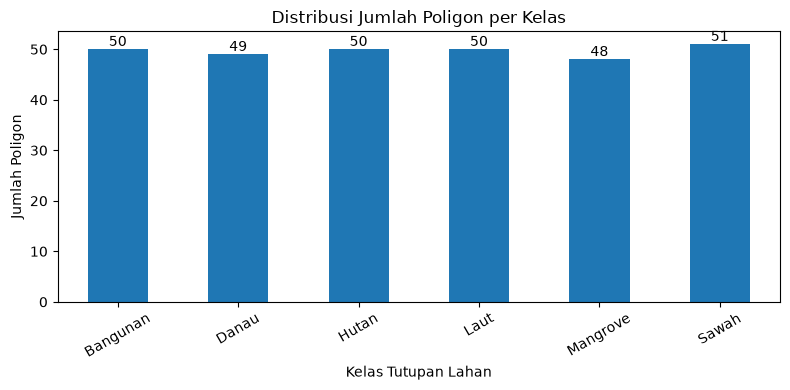

label_teks
Bangunan    50
Danau       49
Hutan       50
Laut        50
Mangrove    48
Sawah       51
Name: poligon_id, dtype: int64
Total poligon: 298


In [ ]:
# Menghitung jumlah poligon unik per kelas
jumlah_poligon = df.groupby('label_teks')['poligon_id'].nunique()

# Visualisasi
ax = jumlah_poligon.plot(kind='bar', figsize=(8, 4))

plt.title('Distribusi Jumlah Poligon per Kelas')
plt.xlabel('Kelas Tutupan Lahan')
plt.ylabel('Jumlah Poligon')
plt.xticks(rotation=30)

# Menampilkan angka di atas batang
for i, nilai in enumerate(jumlah_poligon):
    ax.text(i, nilai, str(nilai), ha='center', va='bottom')

plt.tight_layout()
plt.show()

print(jumlah_poligon)
print("Total poligon:", jumlah_poligon.sum())

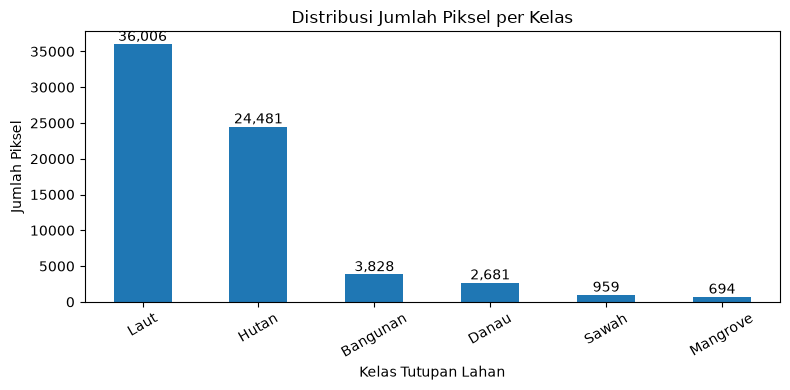

label_teks
Laut        36006
Hutan       24481
Bangunan     3828
Danau        2681
Sawah         959
Mangrove      694
Name: count, dtype: int64
Total seluruh piksel: 68,649


In [ ]:
# Menghitung jumlah piksel per kelas
jumlah_piksel = df['label_teks'].value_counts()

# Visualisasi
ax_piksel = jumlah_piksel.plot(kind='bar', figsize=(8, 4), color='#1f77b4')

plt.title('Distribusi Jumlah Piksel per Kelas')
plt.xlabel('Kelas Tutupan Lahan')
plt.ylabel('Jumlah Piksel')
plt.xticks(rotation=30)

# Menampilkan angka dengan format ribuan di atas batang
for i, nilai in enumerate(jumlah_piksel):
    ax_piksel.text(i, nilai, f'{nilai:,}', ha='center', va='bottom')

plt.tight_layout()
plt.show()

print(jumlah_piksel)
print(f"Total seluruh piksel: {jumlah_piksel.sum():,}")

C:\Users\Administrator\AppData\Local\Temp\ipykernel_11588\2002556827.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='label_teks', y='NDVI', data=df, palette='Set2')


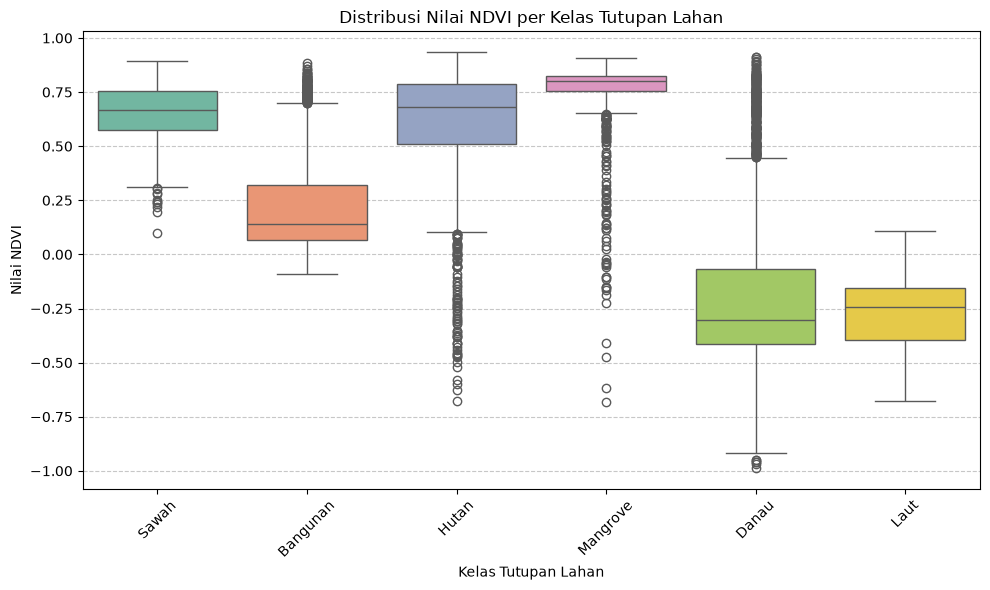

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.boxplot(x='label_teks', y='NDVI', data=df, palette='Set2')

plt.title('Distribusi Nilai NDVI per Kelas Tutupan Lahan')
plt.xlabel('Kelas Tutupan Lahan')
plt.ylabel('Nilai NDVI')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

In [ ]:
# Ringkasan distribusi kelas dengan persentase
kelas_summary = df['label_teks'].value_counts().reset_index()
kelas_summary.columns = ['kelas', 'jumlah_piksel']

kelas_summary

,kelas,jumlah_piksel
0,Laut,36006
1,Hutan,24481
2,Bangunan,3828
3,Danau,2681
4,Sawah,959
5,Mangrove,694


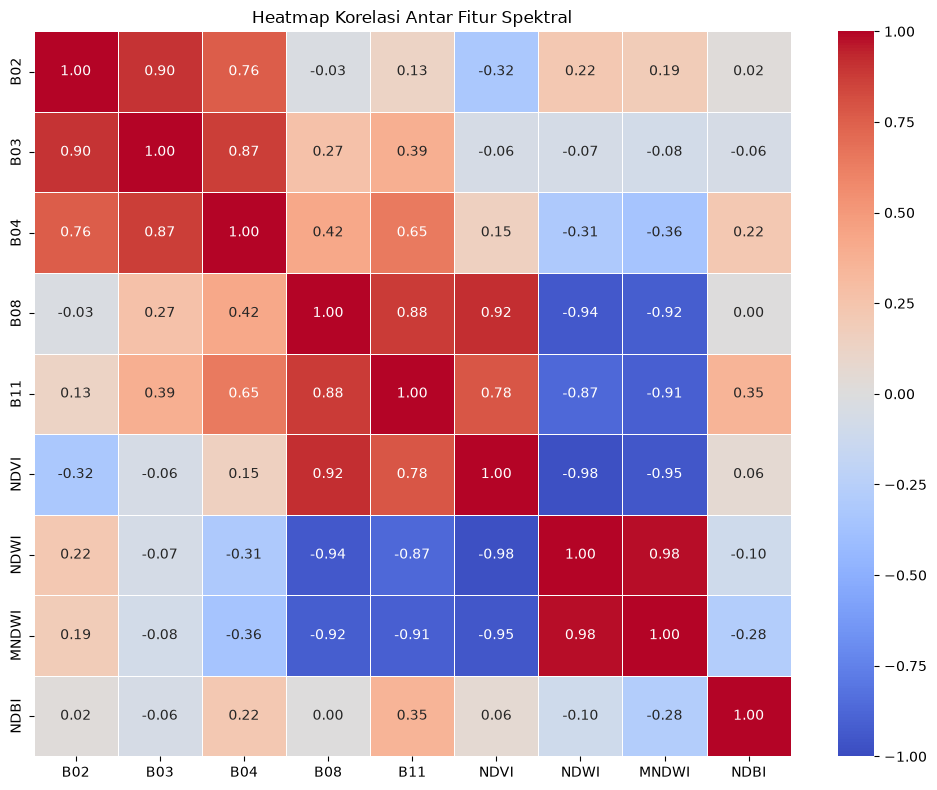

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Menghitung korelasi antar fitur
feat = ['B02', 'B03', 'B04', 'B08', 'B11', 'NDVI', 'NDWI', 'MNDWI', 'NDBI']
correlation = df[feat].corr()

# Visualisasi Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(
    correlation, 
    annot=True,         # Menampilkan nilai angka korelasi
    cmap='coolwarm',    # Skema warna (merah=korelasi positif, biru=korelasi negatif)
    fmt='.2f',          # Format 2 angka desimal
    linewidths=0.5, 
    vmin=-1, vmax=1     # Rentang korelasi ideal
)

plt.title('Heatmap Korelasi Antar Fitur Spektral')
plt.tight_layout()
plt.show()

In [ ]:
# Statistik ringkas per kelas
summary = df.groupby('label_teks')[['NDVI', 'NDWI', 'MNDWI', 'NDBI']].describe()

# Meratakan Multi-Index pada kolom agar lebih rapi
summary.columns = ['_'.join(col).strip() for col in summary.columns.values]

kolom_penting = [
    'NDVI_mean', 'NDVI_min', 'NDVI_max',
    'NDWI_mean', 'NDWI_min', 'NDWI_max',
    'MNDWI_mean', 'MNDWI_min', 'MNDWI_max',
    'NDBI_mean', 'NDBI_min', 'NDBI_max'
]

summary_rapi = summary[kolom_penting].round(3)
summary_rapi

,NDVI_mean,NDVI_min,NDVI_max,NDWI_mean,NDWI_min,NDWI_max,MNDWI_mean,MNDWI_min,MNDWI_max,NDBI_mean,NDBI_min,NDBI_max
label_teks,,,,,,,,,,,,
Bangunan,0.216,-0.088,0.884,-0.263,-0.764,0.312,-0.346,-0.719,0.403,0.085,-0.489,0.490
Danau,-0.186,-0.988,0.910,0.383,-0.773,0.994,0.440,-0.630,0.915,-0.086,-0.802,0.974
Hutan,0.641,-0.676,0.935,-0.604,-0.852,0.839,-0.538,-0.816,0.835,-0.108,-0.699,0.345
Laut,-0.276,-0.676,0.106,0.551,0.085,0.812,0.639,0.064,0.910,-0.162,-0.792,0.190
Mangrove,0.731,-0.682,0.906,-0.605,-0.797,0.711,-0.280,-0.531,0.807,-0.407,-0.718,0.160
Sawah,0.655,0.100,0.891,-0.542,-0.796,0.012,-0.326,-0.566,0.497,-0.270,-0.540,0.105


C:\Users\Administrator\AppData\Local\Temp\ipykernel_11588\2300831627.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


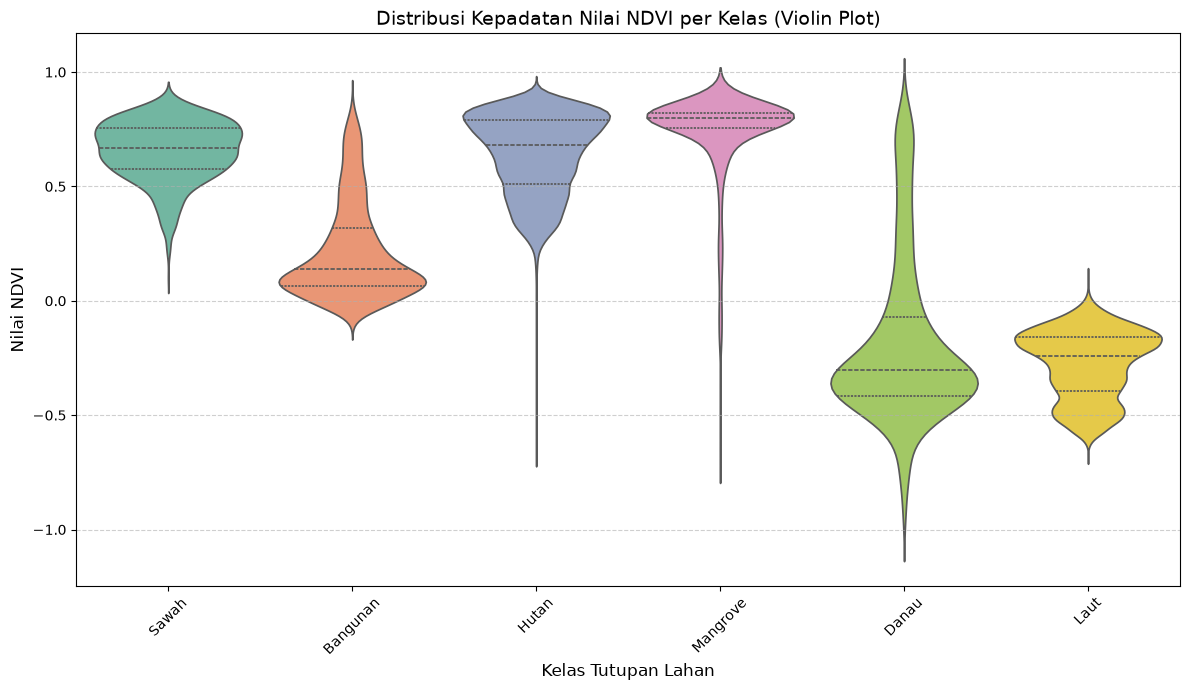

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 7))

# Membuat Violin Plot
sns.violinplot(
    x='label_teks', 
    y='NDVI', 
    data=df, 
    palette='Set2', 
    inner='quartile' # Menampilkan garis kuartil di dalam "biola"
)

plt.title('Distribusi Kepadatan Nilai NDVI per Kelas (Violin Plot)', fontsize=14)
plt.xlabel('Kelas Tutupan Lahan', fontsize=12)
plt.ylabel('Nilai NDVI', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

C:\Users\Administrator\AppData\Local\Temp\ipykernel_11588\3387765941.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


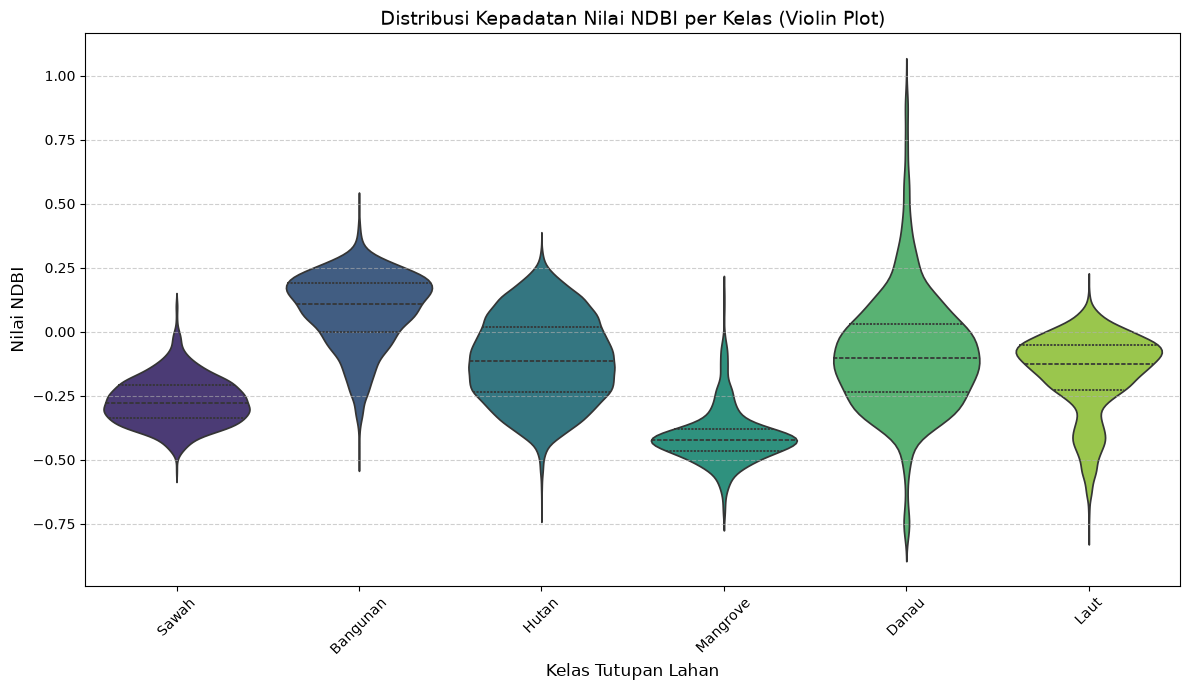

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 7))

# Membuat Violin Plot untuk NDBI
sns.violinplot(
    x='label_teks', 
    y='NDBI', 
    data=df, 
    palette='viridis', 
    inner='quartile' # Menampilkan garis kuartil di dalam "biola"
)

plt.title('Distribusi Kepadatan Nilai NDBI per Kelas (Violin Plot)', fontsize=14)
plt.xlabel('Kelas Tutupan Lahan', fontsize=12)
plt.ylabel('Nilai NDBI', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

In [ ]:
# Pastikan variabel 'feat' sudah didefinisikan sebelumnya
feat = ['B02', 'B03', 'B04', 'B08', 'B11', 'NDVI', 'NDWI', 'MNDWI', 'NDBI']

# Menghitung nilai rata-rata per kelas (Profil Spektral)
mean_by_class = df.groupby('label_teks')[feat].mean().round(4)
mean_by_class

,B02,B03,B04,B08,B11,NDVI,NDWI,MNDWI,NDBI
label_teks,,,,,,,,,
Bangunan,1019.1029,1190.8521,1330.3341,2006.4193,2370.8080,0.2157,-0.2632,-0.3460,0.0849
Danau,333.5062,507.9634,325.2111,447.4998,343.8083,-0.1863,0.3831,0.4403,-0.0861
Hutan,434.9308,648.9817,584.2229,2676.5156,2159.1763,0.6406,-0.6045,-0.5377,-0.1084
Laut,539.6641,536.4648,282.0495,133.6176,91.8603,-0.2765,0.5508,0.6388,-0.1619
Mangrove,344.2349,613.3213,363.3660,2796.3847,1146.3141,0.7314,-0.6050,-0.2803,-0.4072
Sawah,362.1502,582.5506,406.7174,2091.6330,1183.7904,0.6547,-0.5421,-0.3259,-0.2704


In [ ]:
# Kelas dengan jumlah piksel terbesar dan terkecil
class_counts = df['label_teks'].value_counts()
print("Distribusi Jumlah Piksel per Kelas:")
print(class_counts)
print("-" * 30)
print(f"Kelas mayoritas: {class_counts.idxmax()} ({class_counts.max():,})")
print(f"Kelas minoritas: {class_counts.idxmin()} ({class_counts.min():,})")

Distribusi Jumlah Piksel per Kelas:
label_teks
Laut        36006
Hutan       24481
Bangunan     3828
Danau        2681
Sawah         959
Mangrove      694
Name: count, dtype: int64
------------------------------
Kelas mayoritas: Laut (36,006)
Kelas minoritas: Mangrove (694)


In [ ]:
# Persentase distribusi kelas
class_pct = (df['label_teks'].value_counts() / len(df) * 100).round(2)

print("Persentase Distribusi Kelas (%):")
print(class_pct)

Persentase Distribusi Kelas (%):
label_teks
Laut        52.45
Hutan       35.66
Bangunan     5.58
Danau        3.91
Sawah        1.40
Mangrove     1.01
Name: count, dtype: float64


#### Penentuan Fitur

Penentuan fitur adalah pemilihan variabel yang digunakan model untuk mengenali jenis tutupan lahan. Fitur yang digunakan terdiri dari 5 band Sentinel-2 dan 4 indeks spektral, sehingga terdapat 9 fitur sebagai dasar klasifikasi.

In [ ]:
fitur = [
    'B02', 'B03', 'B04', 'B08', 'B11',
    'NDVI', 'NDWI', 'MNDWI', 'NDBI'
]

X = df[fitur]
y = df['label_teks']

#### Pembagian Data Training dan Testing 80:20

Pembagian data 80:20 adalah proses membagi dataset menjadi 80% data training untuk melatih model mengenali pola tutupan lahan dan 20% data testing untuk mengukur kemampuan model dalam mengklasifikasikan data yang belum pernah dipelajari.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print('Data training:', len(X_train))
print('Data testing :', len(X_test))

Data training: 54919
Data testing : 13730


#### StandardScaler

StandardScaler adalah metode untuk menyamakan skala nilai setiap fitur agar memiliki rata-rata 0 dan standar deviasi 1. Tujuannya supaya fitur dengan nilai besar tidak mendominasi perhitungan jarak pada algoritma KNN.

In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## Modeling

Modeling adalah tahap membangun dan melatih model K-Nearest Neighbors (KNN) menggunakan data training. KNN mengklasifikasikan tutupan lahan berdasarkan kemiripan fitur dengan sejumlah data terdekat.

In [ ]:
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train)

y_pred_knn = knn_model.predict(X_test_scaled)

## Evaluation

### Accuracy dan F1-Score

Accuracy adalah ukuran persentase prediksi model yang benar dari seluruh data uji. Sementara itu, F1-Score adalah ukuran keseimbangan antara precision (ketepatan prediksi) dan recall (kemampuan mengenali kelas), terutama saat jumlah data setiap kelas tidak seimbang.

In [ ]:
accuracy = accuracy_score(y_test, y_pred_knn)
f1_macro = f1_score(y_test, y_pred_knn, average='macro')
f1_weighted = f1_score(y_test, y_pred_knn, average='weighted')

print(f'Accuracy    : {accuracy:.4f}')
print(f'F1 Macro   : {f1_macro:.4f}')
print(f'F1 Weighted: {f1_weighted:.4f}')

Accuracy    : 0.9676
F1 Macro   : 0.8562
F1 Weighted: 0.9668


Model KNN memperoleh **Accuracy 96,76%**, menunjukkan sebagian besar data uji berhasil diklasifikasikan dengan benar. **F1 Macro 85,62%** menunjukkan performa antar kelas belum merata, sedangkan **F1 Weighted 96,68%** menunjukkan performa keseluruhan yang tinggi dengan mempertimbangkan jumlah data setiap kelas.

### Classification Report

In [ ]:
print(classification_report(y_test, y_pred_knn))

              precision    recall  f1-score   support

    Bangunan       0.88      0.80      0.84       766
       Danau       0.96      0.84      0.89       536
       Hutan       0.95      0.98      0.96      4896
        Laut       1.00      1.00      1.00      7201
    Mangrove       0.76      0.74      0.75       139
       Sawah       0.74      0.65      0.69       192

    accuracy                           0.97     13730
   macro avg       0.88      0.83      0.86     13730
weighted avg       0.97      0.97      0.97     13730



**Classification Report** menunjukkan kemampuan model mengenali setiap kelas melalui *precision* (ketepatan prediksi), *recall* (kemampuan menemukan kelas), *F1-score* (keseimbangan keduanya), dan *support* (jumlah data uji). Hasil menunjukkan **Laut** memiliki performa tertinggi dengan F1-score **1,00 (100%)**, sedangkan **Sawah** terendah dengan **0,69 (69%)**. Artinya, model sangat baik mengenali perairan laut, tetapi masih kesulitan membedakan beberapa kelas tutupan lahan.

### Confusion Matrix

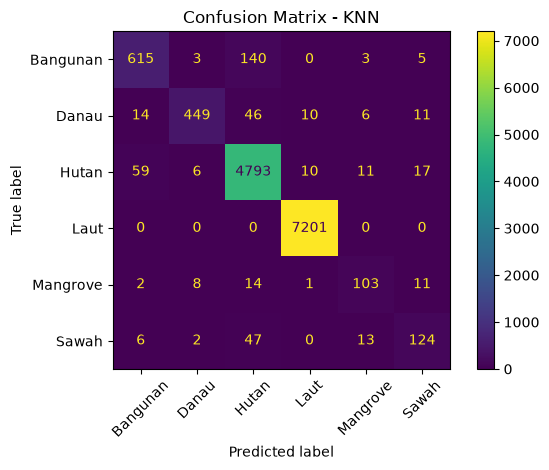

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_knn,
    xticks_rotation=45
)

plt.title('Confusion Matrix - KNN')
plt.tight_layout()
plt.show()

**Confusion Matrix** menunjukkan jumlah prediksi benar dan salah pada setiap kelas. Nilai diagonal menunjukkan prediksi yang benar, sedangkan nilai di luar diagonal menunjukkan kesalahan klasifikasi. Pada hasil ini, kelas **Laut** memiliki prediksi paling baik karena seluruh data terklasifikasi benar, sedangkan kesalahan masih terlihat pada kelas seperti **Bangunan**, **Sawah**, dan **Mangrove** yang beberapa datanya diprediksi sebagai kelas lain.

### Evaluasi Tingkat Polygon

Prediksi piksel pada data uji dikelompokkan berdasarkan `poligon_id`. Kelas akhir setiap polygon ditentukan menggunakan mayoritas prediksi piksel.

In [ ]:
hasil_test = df.loc[
    X_test.index,
    ['poligon_id', 'label_teks']
].copy()

hasil_test['prediksi'] = y_pred_knn

eval_poligon = (
    hasil_test
    .groupby('poligon_id')
    .agg(
        kelas_aktual=('label_teks', 'first'),
        kelas_prediksi=('prediksi', lambda x: x.mode().iloc[0]),
        jumlah_piksel=('prediksi', 'size')
    )
    .reset_index()
)

eval_poligon['benar'] = (
    eval_poligon['kelas_aktual'] ==
    eval_poligon['kelas_prediksi']
)

print('Total polygon uji:', len(eval_poligon))
print('Polygon benar    :', int(eval_poligon['benar'].sum()))
print('Polygon salah    :', int((~eval_poligon['benar']).sum()))
print('Akurasi polygon  :', round(eval_poligon['benar'].mean(), 4))

Total polygon uji: 255
Polygon benar    : 210
Polygon salah    : 45
Akurasi polygon  : 0.8235


## Peta Interaktif Evaluasi Polygon

In [ ]:
gdf_eval = gdf.merge(
    eval_poligon,
    on='poligon_id',
    how='left'
)

WARNA_KELAS = {
    'Sawah': '#90EE90',
    'Bangunan': '#FF0000',
    'Hutan': '#008000',
    'Mangrove': '#006400',
    'Danau': '#ADD8E6',
    'Laut': '#0000FF'
}

minx, miny, maxx, maxy = gdf_eval.total_bounds

m = folium.Map(
    location=[(miny + maxy) / 2, (minx + maxx) / 2],
    zoom_start=8,
    tiles=None
)

folium.TileLayer(
    tiles='https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}',
    attr='Esri World Imagery',
    name='Esri Satellite',
    overlay=False
).add_to(m)

folium.TileLayer('OpenStreetMap', name='OpenStreetMap').add_to(m)

for kelas, warna in WARNA_KELAS.items():
    sub = gdf_eval[gdf_eval['label_teks'] == kelas]

    folium.GeoJson(
        sub,
        name=kelas,
        style_function=lambda feature, warna=warna: {
            'color': warna,
            'fillColor': warna,
            'weight': 2,
            'fillOpacity': 0.45
        },
        tooltip=folium.GeoJsonTooltip(
            fields=['poligon_id', 'label_teks', 'kelas_prediksi', 'benar'],
            aliases=['Polygon:', 'Kelas Asli:', 'Prediksi:', 'Benar:']
        )
    ).add_to(m)

salah = gdf_eval[gdf_eval['benar'] == False]

if len(salah) > 0:
    folium.GeoJson(
        salah,
        name='Salah Klasifikasi',
        style_function=lambda feature: {
            'color': '#ff7800',
            'weight': 4,
            'fill': False,
            'dashArray': '6, 4'
        }
    ).add_to(m)

folium.LayerControl(collapsed=False).add_to(m)
m.fit_bounds([[miny, minx], [maxy, maxx]])

m.save(HASIL / 'peta_evaluasi_knn.html')
m

In [ ]:
joblib.dump(knn_model, HASIL / 'model_knn.pkl')
joblib.dump(scaler, HASIL / 'scaler_knn.pkl')

eval_poligon.to_csv(
    HASIL / 'evaluasi_poligon.csv',
    index=False
)

print('Model, scaler, dan evaluasi polygon berhasil disimpan.')

Model, scaler, dan evaluasi polygon berhasil disimpan.


In [ ]:
import json
from pathlib import Path

# Hasil evaluasi KNN
metrik = {
    "accuracy": 0.9676,
    "f1_macro": 0.8562,
    "f1_weighted": 0.9668
}

# Simpan ke JSON
file = HASIL / 'metrik_knn.json'
file.parent.mkdir(parents=True, exist_ok=True)

with open(file, "w") as f:
    json.dump(metrik, f, indent=4)

print("Berhasil disimpan:", file.resolve())

Berhasil disimpan: C:\project\PSD\hasil\metrik_knn.json


## Peta Utuh Pixel

✅ Semua file ditemukan. Memulai proses klasifikasi dan pembuatan peta...
✅ Peta berhasil dibuat!



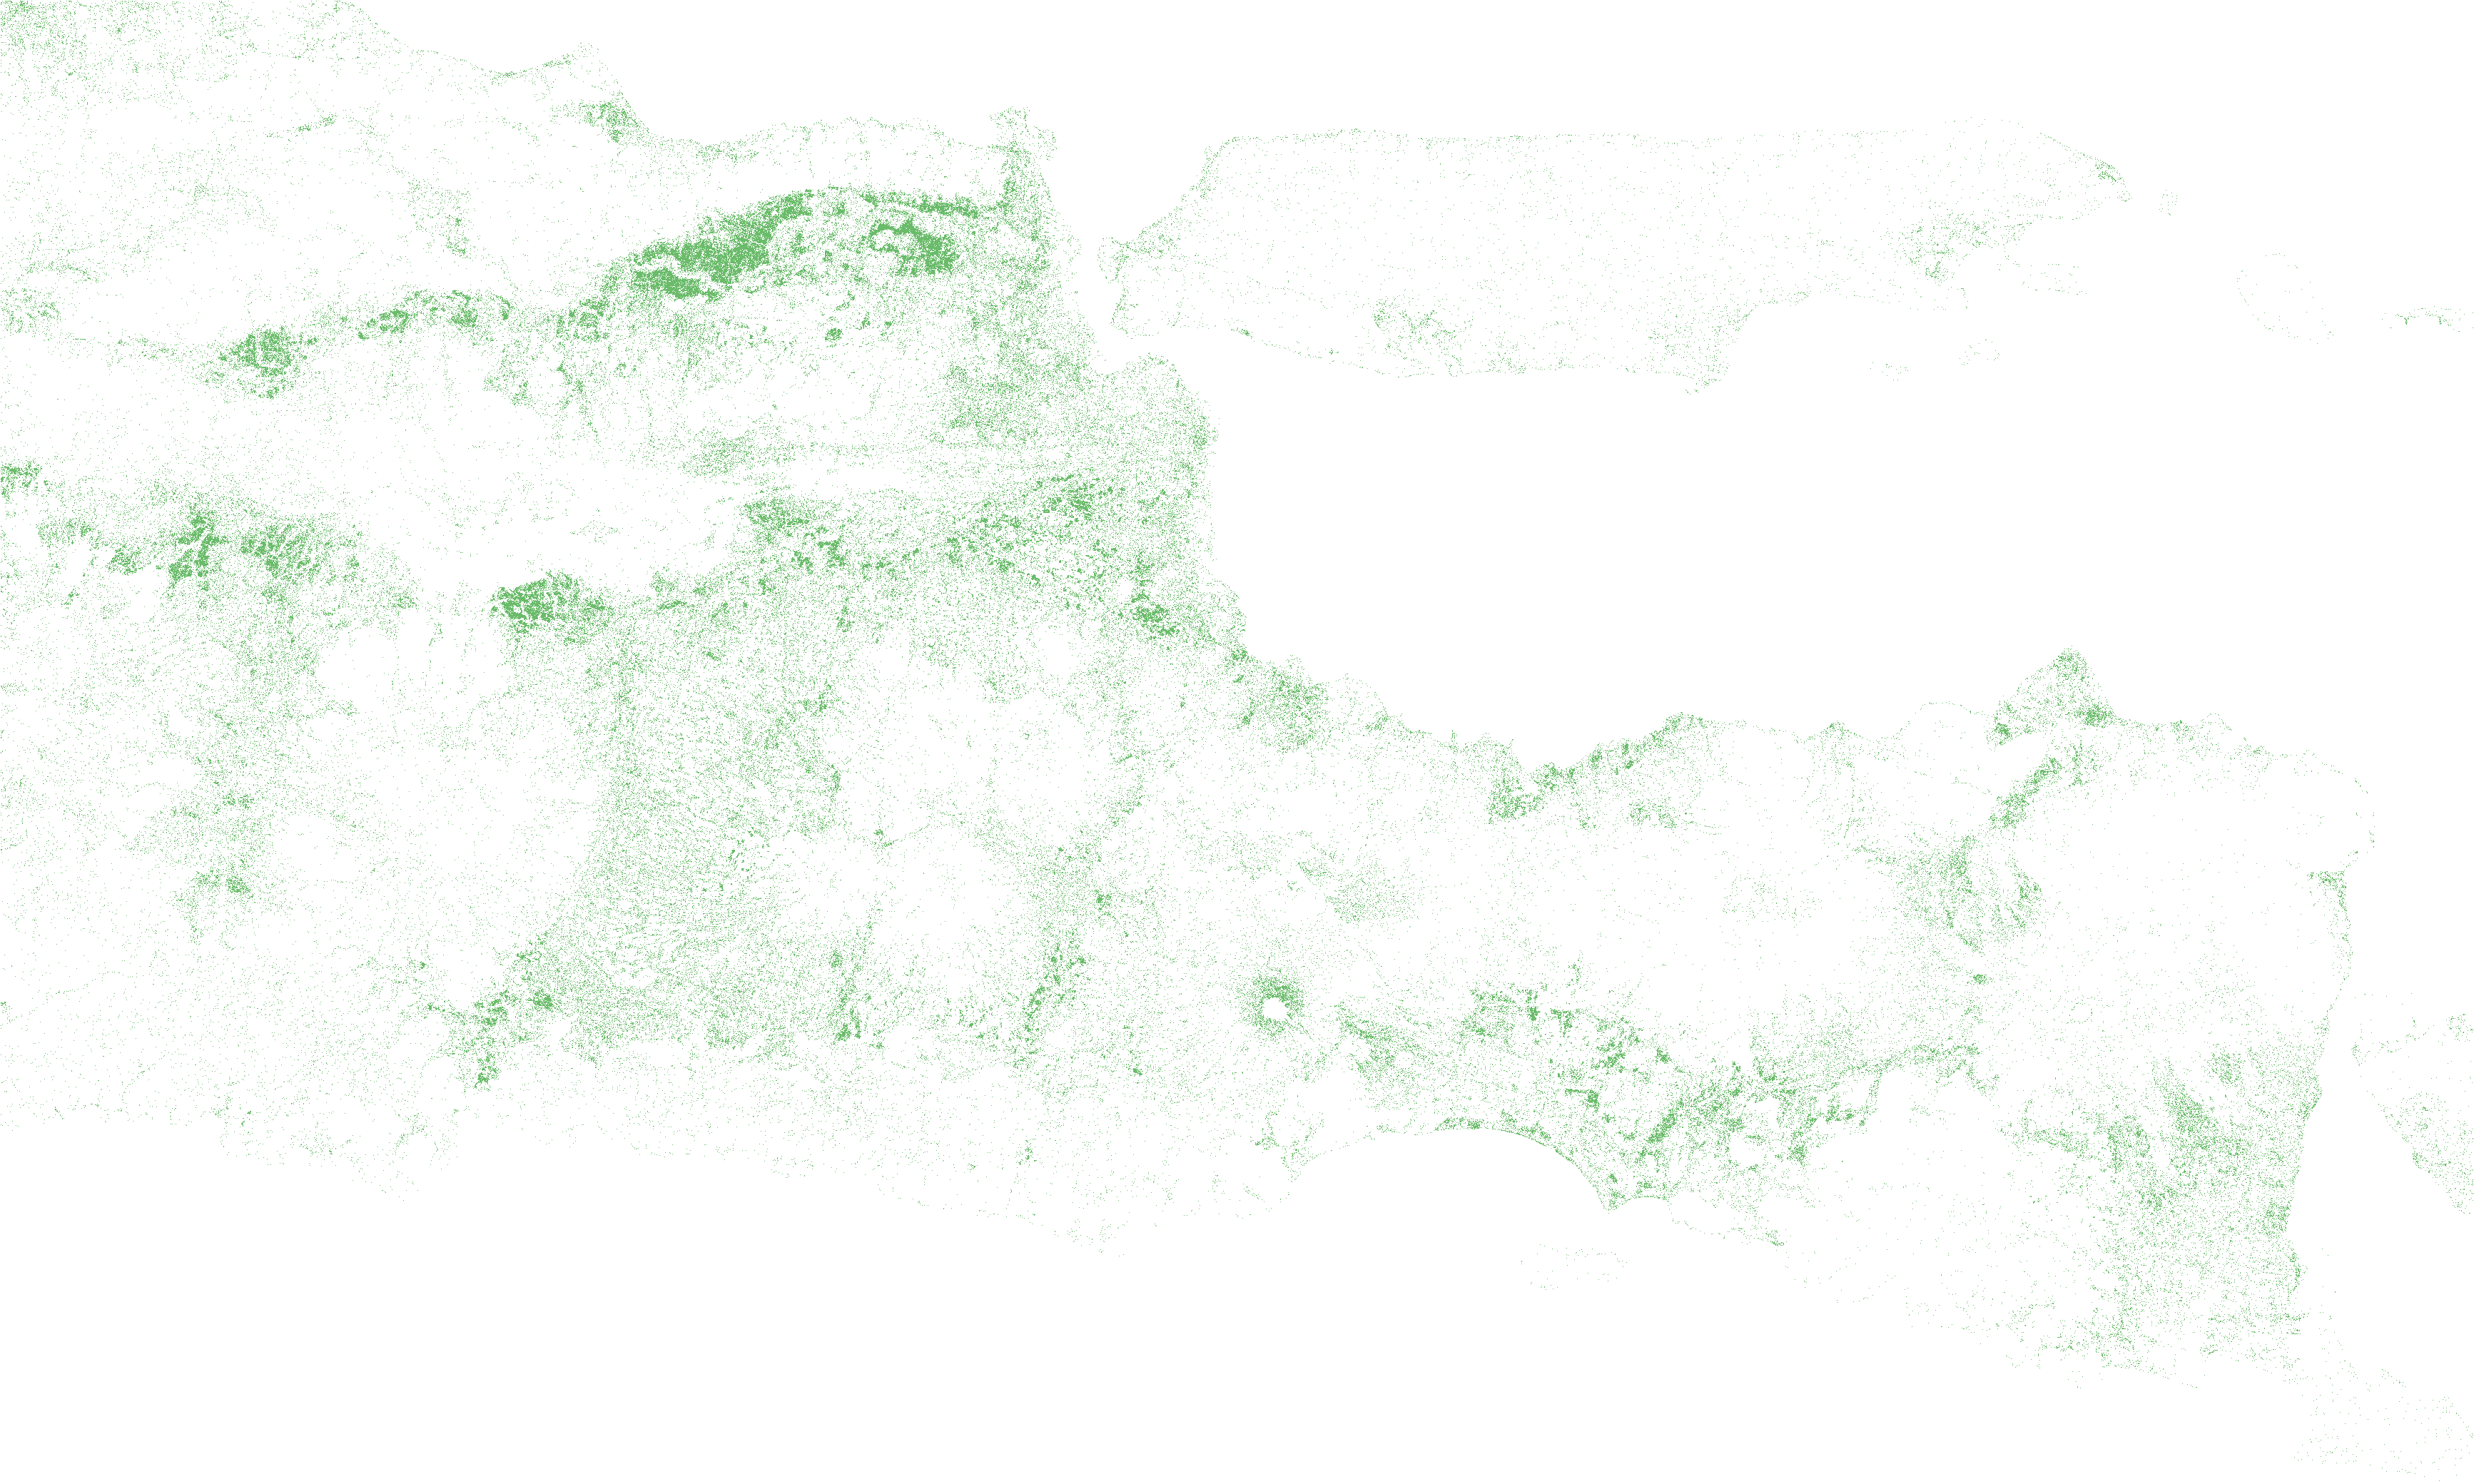
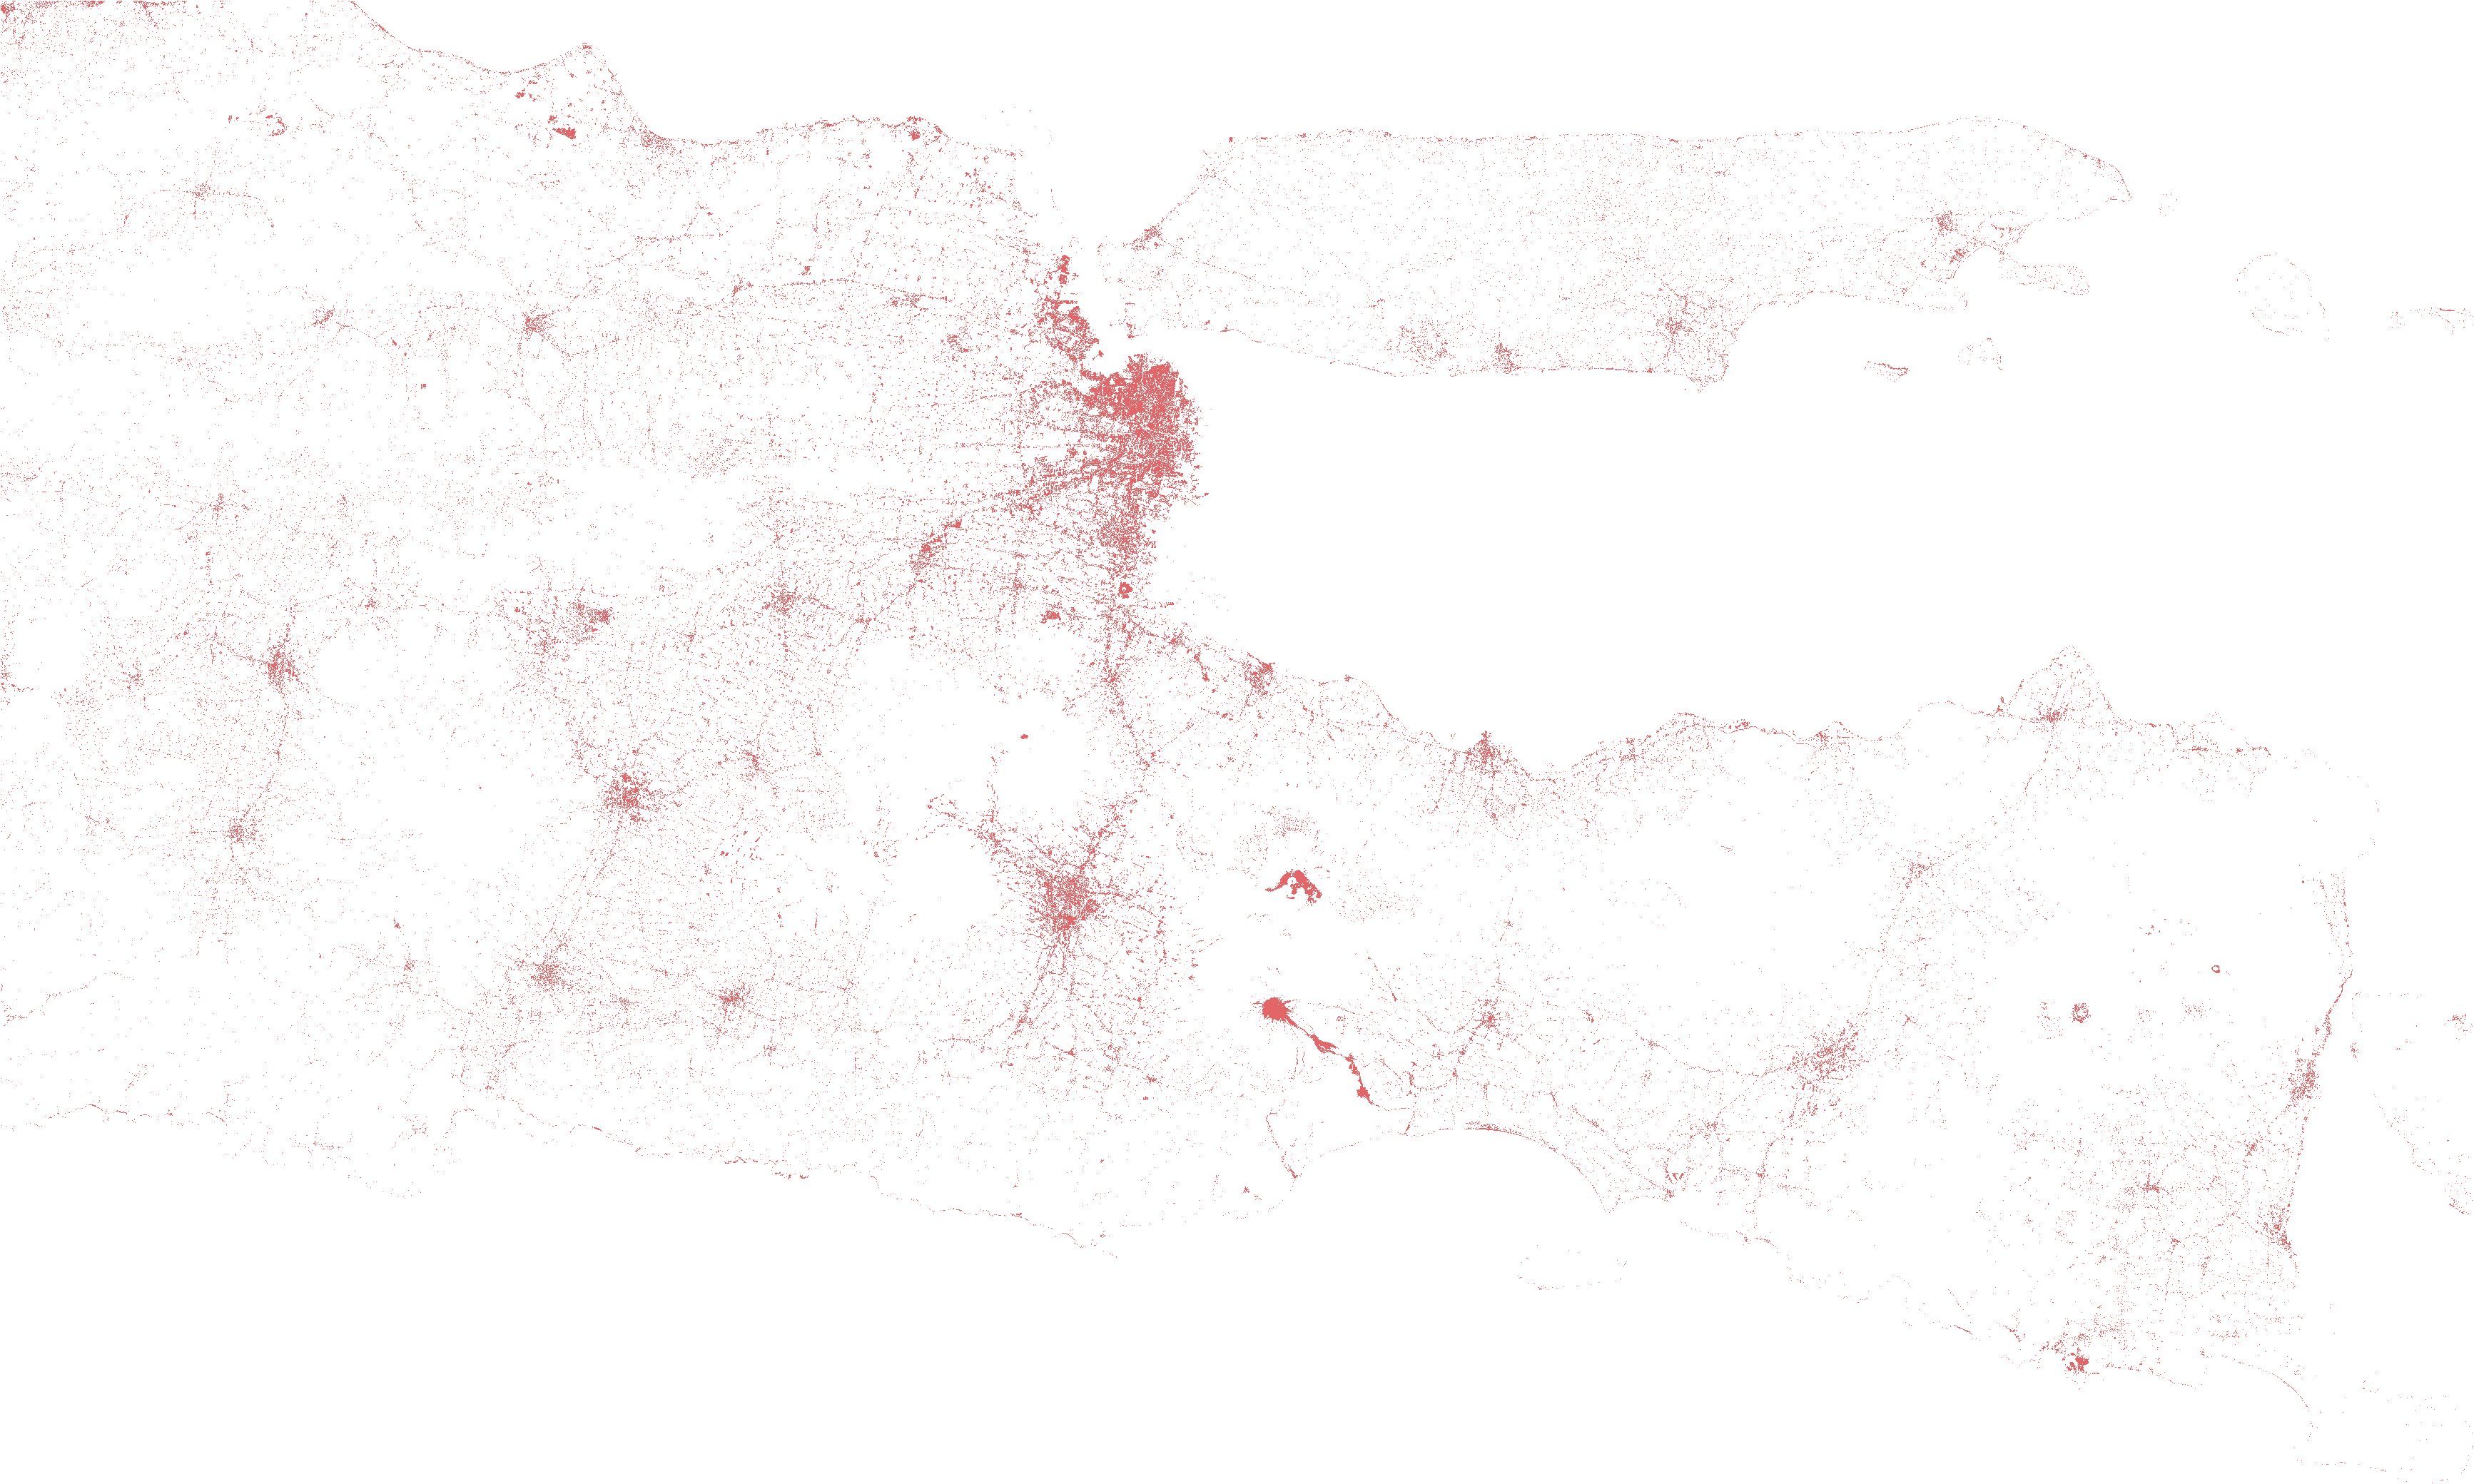
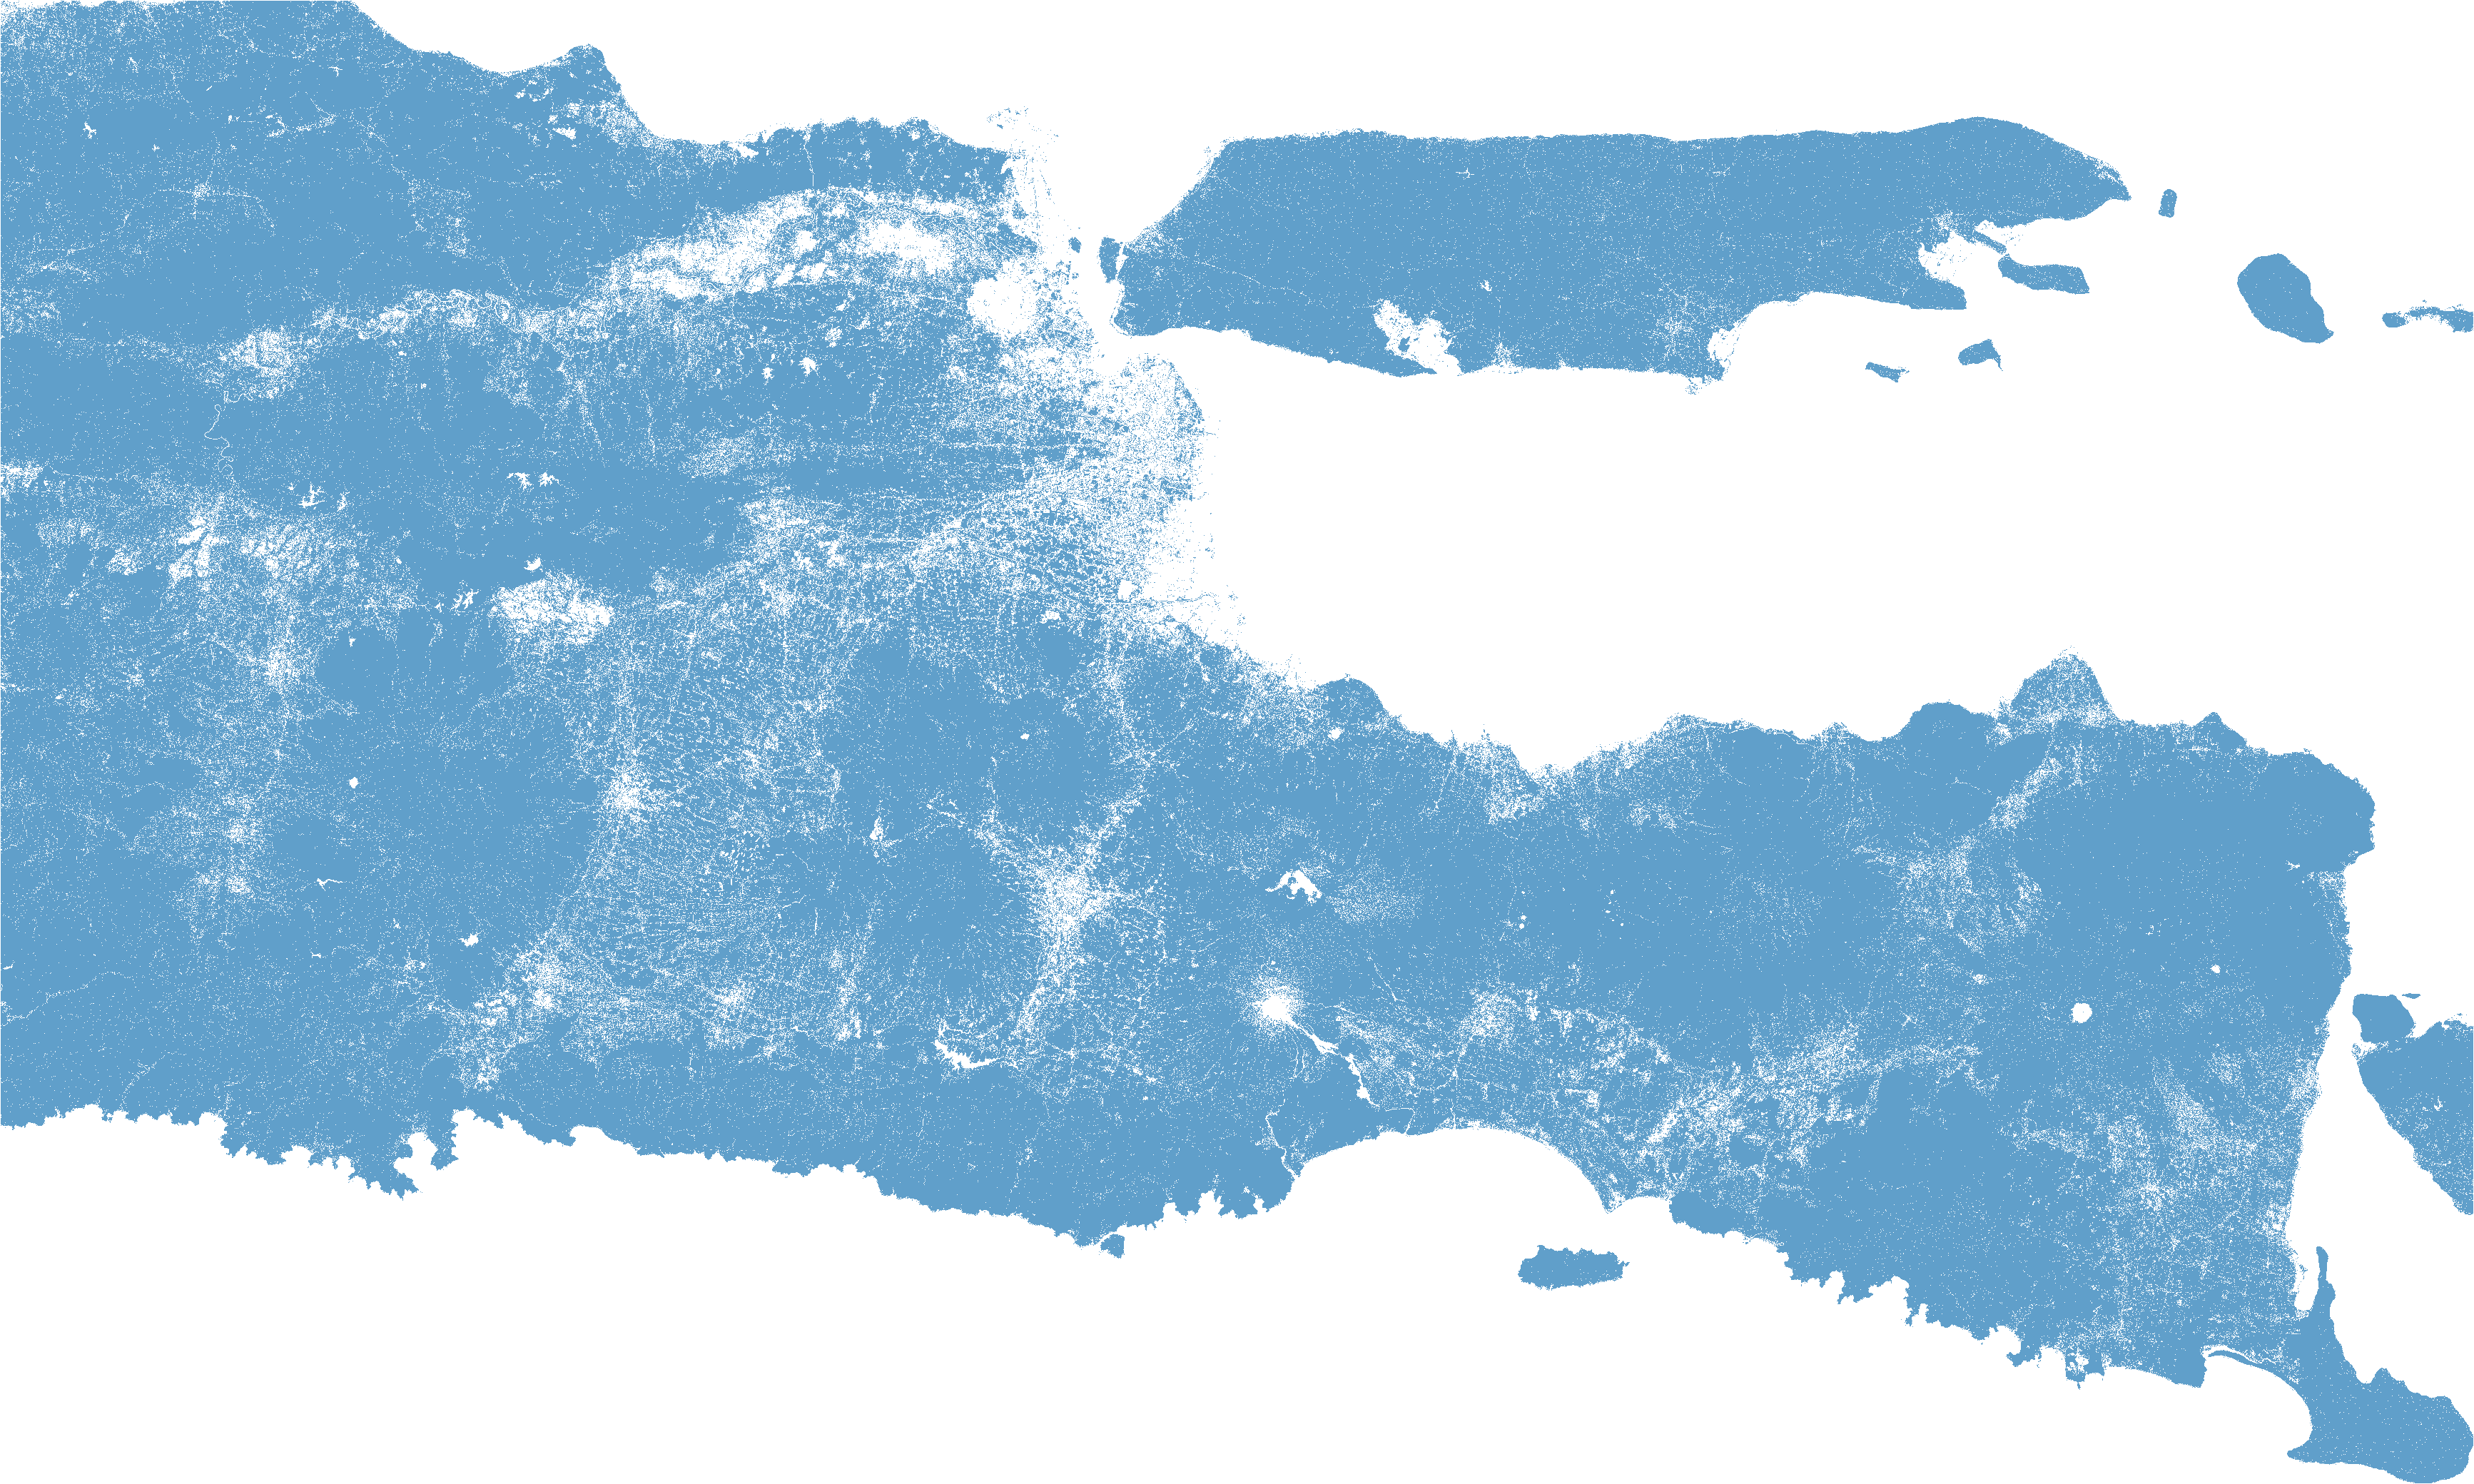
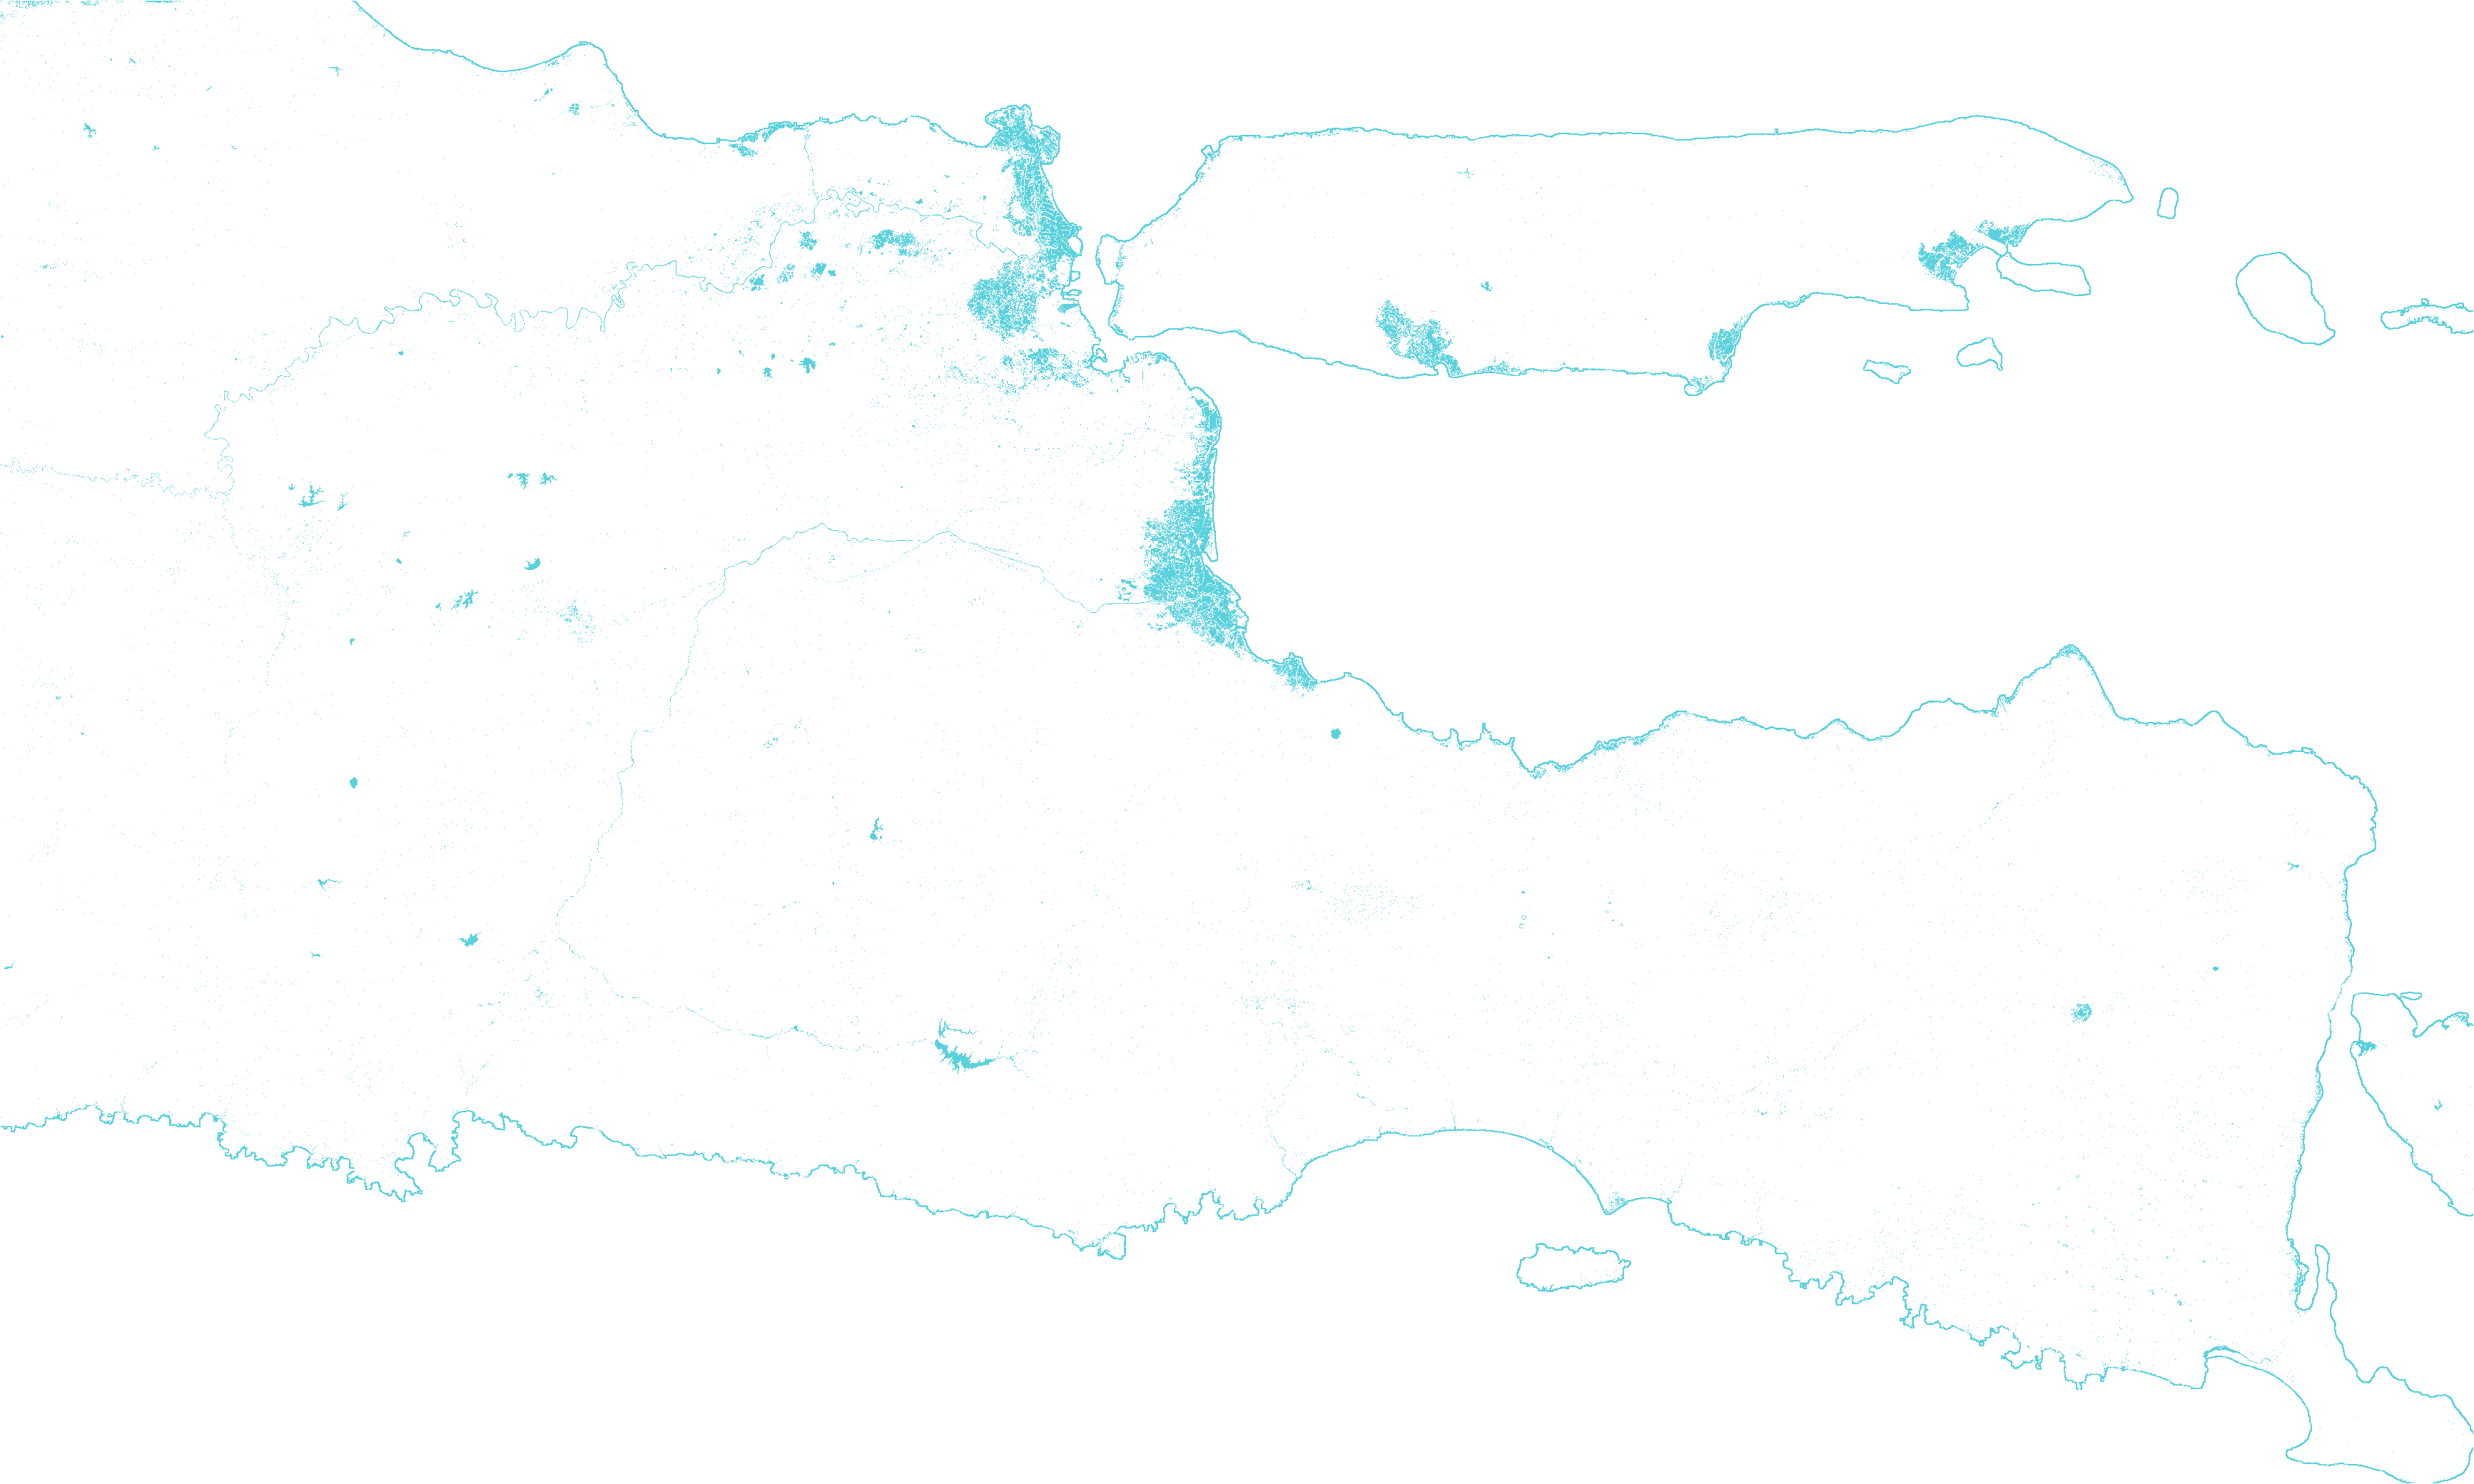
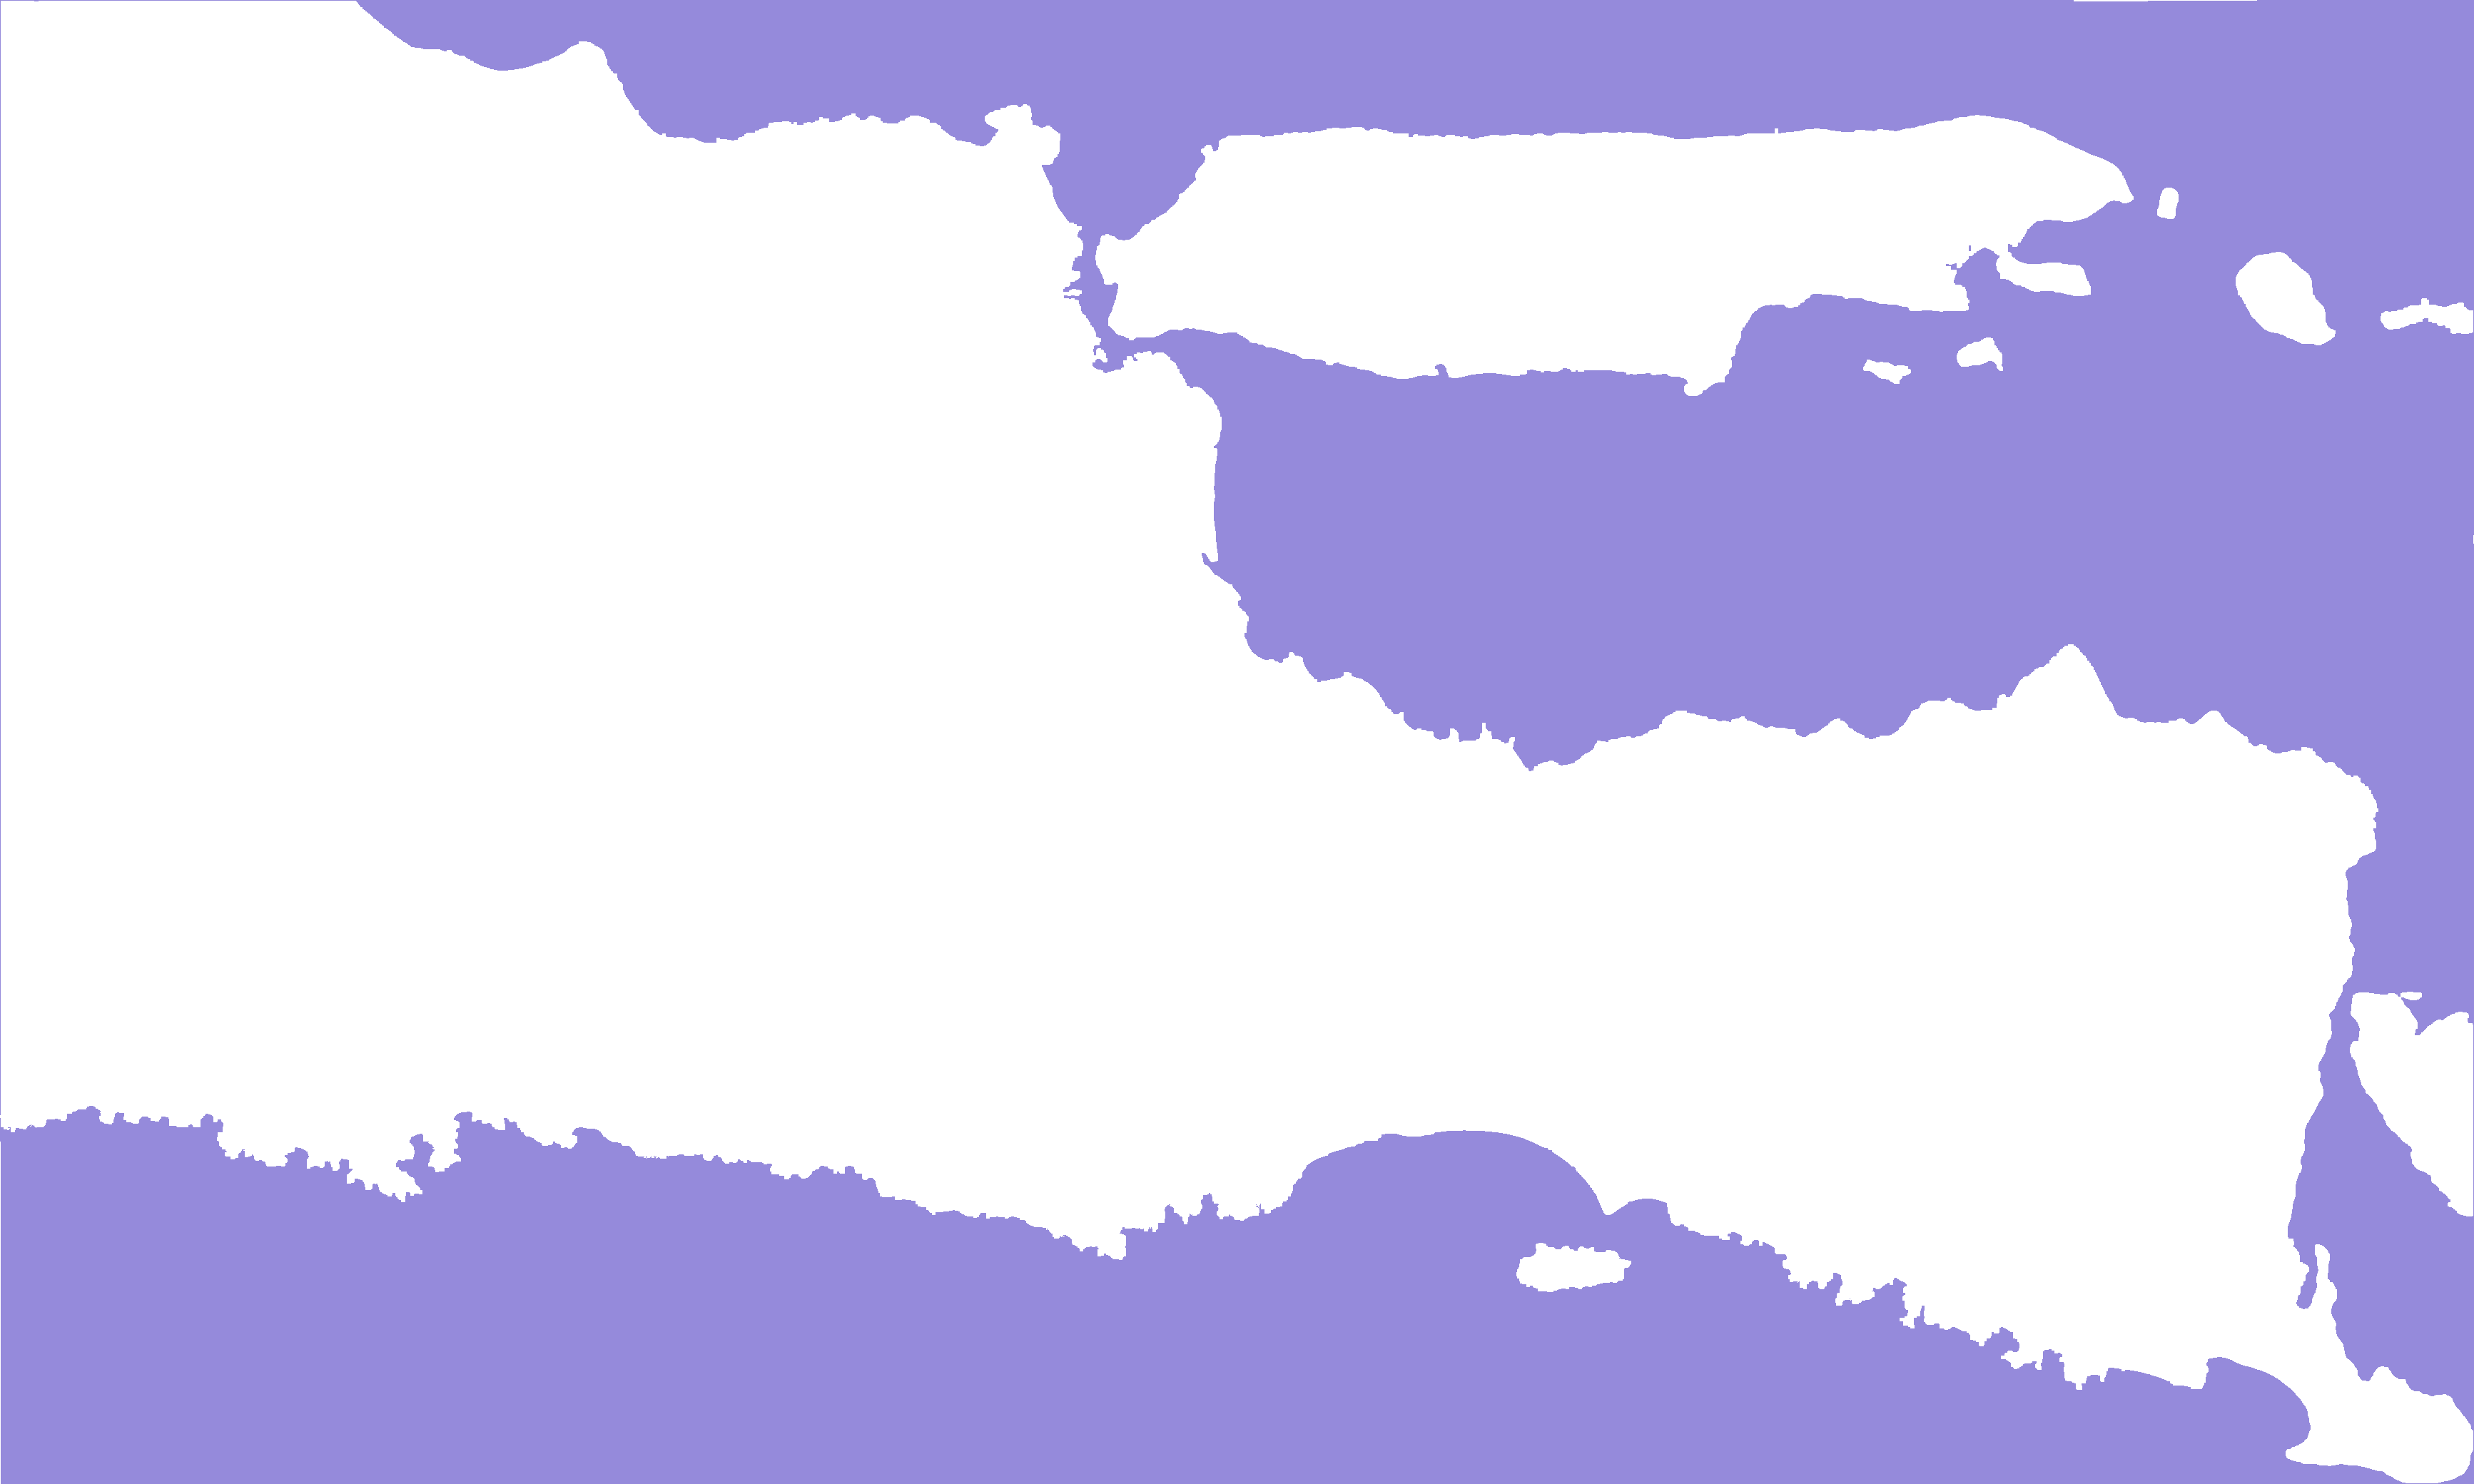
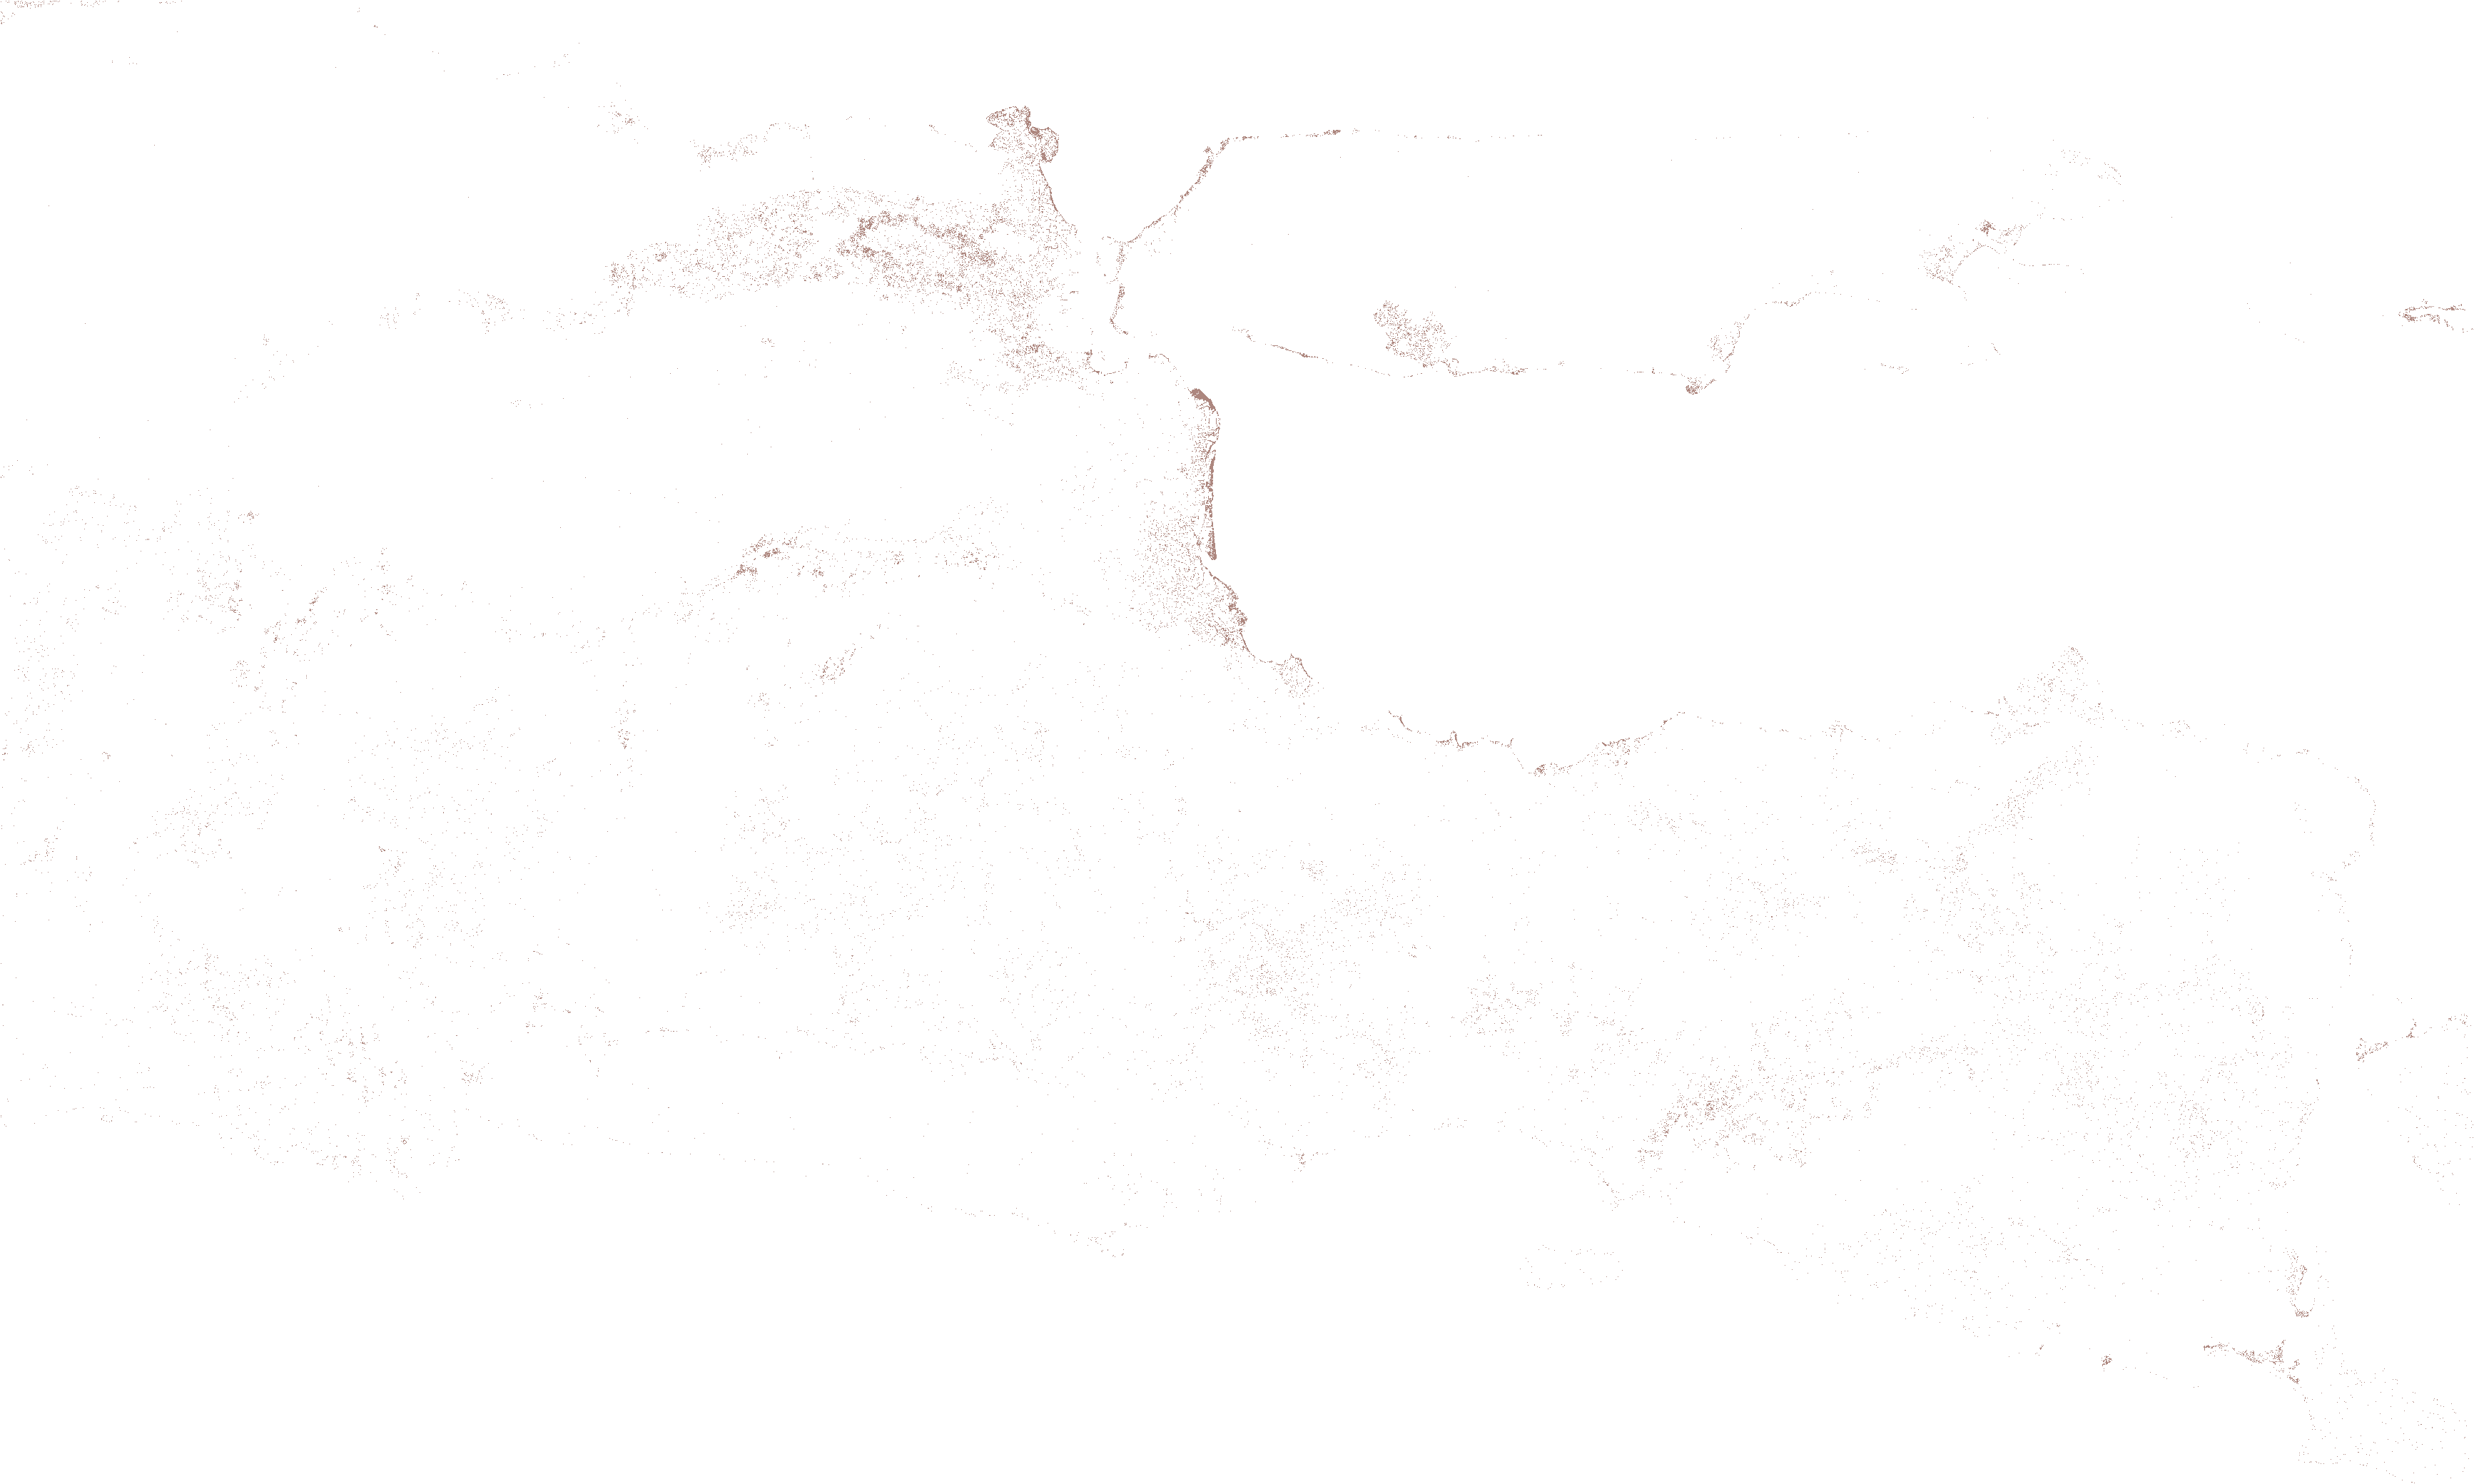

In [ ]:
import os
import warnings
import rasterio
import numpy as np
import folium
import joblib
from scipy.ndimage import label, binary_closing, binary_fill_holes, binary_dilation

warnings.filterwarnings('ignore')

# ==========================================
# 1. SETUP LOKASI FILE (ABSOLUTE PATH)
# ==========================================
# Ganti nama file jatim_250m.tif sesuai dengan lokasi aslinya di komputer Anda
FILE_RASTER = 'data/raw/hasil_citra_uts.tif'
FILE_MODEL  = 'hasil/model_knn.pkl'
FILE_SCALER = 'hasil/scaler_knn.pkl'

# Fungsi pembantu: konversi kode warna hex (#RRGGBB) ke (R, G, B)
def hex_to_rgb(hex_code):
    hex_code = hex_code.lstrip('#')
    return tuple(int(hex_code[i:i+2], 16) for i in (0, 2, 4))

# Cek apakah file raster dan model tersedia sebelum memproses
if not os.path.exists(FILE_RASTER):
    print(f"❌ GAGAL: File raster tidak ditemukan di {FILE_RASTER}")
elif not os.path.exists(FILE_MODEL) or not os.path.exists(FILE_SCALER):
    print("❌ GAGAL: File model_knn.pkl atau scaler_knn.pkl tidak ditemukan di folder hasil.")
else:
    print("✅ Semua file ditemukan. Memulai proses klasifikasi dan pembuatan peta...")
    
    # Load Model dan Scaler
    knn_model = joblib.load(FILE_MODEL)
    scaler = joblib.load(FILE_SCALER)

    # ==========================================
    # 2. PROSES EKSTRAKSI RASTER & INDEKS
    # ==========================================
    with rasterio.open(FILE_RASTER) as src:
        b2 = src.read(1).astype(float)
        b3 = src.read(2).astype(float)
        b4 = src.read(3).astype(float)
        b8 = src.read(4).astype(float)
        b11 = src.read(5).astype(float)

        bounds = src.bounds
        img_bounds = [[bounds.bottom, bounds.left], [bounds.top, bounds.right]]
        center_lat = (bounds.bottom + bounds.top) / 2
        center_lon = (bounds.left + bounds.right) / 2

    e = 1e-9
    ndvi = (b8 - b4) / (b8 + b4 + e)
    ndwi = (b3 - b8) / (b3 + b8 + e)
    mndwi = (b3 - b11) / (b3 + b11 + e)
    ndbi = (b11 - b8) / (b11 + b8 + e)

    height, width = b2.shape
    valid_mask = (b2 > 0) & (b2 != -32768) & (b8 > 0) & (b11 > 0)
    valid_mask_1d = valid_mask.flatten()

    features_stack = np.column_stack((
        b2.flatten(), b3.flatten(), b4.flatten(), b8.flatten(), b11.flatten(),
        ndvi.flatten(), ndwi.flatten(), mndwi.flatten(), ndbi.flatten()
    ))

    pred_1d = np.full(height * width, fill_value="", dtype=object)

    if np.any(valid_mask_1d):
        features_valid = features_stack[valid_mask_1d]
        features_scaled = scaler.transform(features_valid)

        # ==========================================
        # 3. PREDIKSI KNN DENGAN CHUNKING
        # ==========================================
        chunk_size = 50000
        n_valid = len(features_valid)
        preds_list = []
        for start in range(0, n_valid, chunk_size):
            end = min(start + chunk_size, n_valid)
            chunk_pred = knn_model.predict(features_scaled[start:end])
            preds_list.append(chunk_pred)

        preds_all_valid = np.concatenate(preds_list)

        # ==========================================
        # 4. HEURISTIK SPASIAL (OBIA & KOREKSI)
        # ==========================================
        # 4.1 Segmentasi Morfologis Daratan Pulau
        daratan_inti = valid_mask & (ndvi > 0.15) & (mndwi < 0.10)
        daratan_morfologi = binary_closing(daratan_inti, structure=np.ones((7, 7)))
        daratan_morfologi = binary_fill_holes(daratan_morfologi)

        labeled_land, _ = label(daratan_morfologi)
        land_sizes = np.bincount(labeled_land.ravel())
        land_sizes[0] = 0

        mask_daratan_2d = np.isin(labeled_land, np.where(land_sizes > 100)[0])
        mask_daratan_2d = binary_dilation(mask_daratan_2d, structure=np.ones((5, 5))) & valid_mask

        mask_laut_murni_2d = valid_mask & ~mask_daratan_2d
        mask_laut_1d = mask_laut_murni_2d.flatten()[valid_mask_1d]
        mask_darat_1d = mask_daratan_2d.flatten()[valid_mask_1d]

        # Koreksi Laut Lepas murni
        preds_all_valid[mask_laut_1d] = 'Laut'

        # 4.2 Danau di daratan
        mndwi_v = mndwi.flatten()[valid_mask_1d]
        b8_v = b8.flatten()[valid_mask_1d]
        ndvi_v = ndvi.flatten()[valid_mask_1d]

        is_air_daratan = mask_darat_1d & (mndwi_v > 0.12) & (b8_v < 1300)
        preds_all_valid[is_air_daratan] = 'Danau'

        # 4.3 Koreksi Biofisik
        false_bangunan = mask_darat_1d & (preds_all_valid == 'Bangunan') & (ndvi_v > 0.25)
        preds_all_valid[false_bangunan & (ndvi_v > 0.45)] = 'Hutan'
        preds_all_valid[false_bangunan & (ndvi_v <= 0.45)] = 'Sawah'

        salah_laut_di_darat = mask_darat_1d & (preds_all_valid == 'Laut')
        preds_all_valid[salah_laut_di_darat & (ndvi_v > 0.40)] = 'Hutan'
        preds_all_valid[salah_laut_di_darat & (ndvi_v <= 0.40) & (ndvi_v > 0.20)] = 'Sawah'
        preds_all_valid[salah_laut_di_darat & (ndvi_v <= 0.20)] = 'Bangunan'

        pred_1d[valid_mask_1d] = preds_all_valid

    pred_2d = pred_1d.reshape((height, width))
    valid_2d = valid_mask

    # ==========================================
    # 5. VISUALISASI PETA FOLIUM & LEGENDA
    # ==========================================
    m_full = folium.Map(
        location=[center_lat, center_lon],
        zoom_start=8,
        tiles='https://mt1.google.com/vt/lyrs=s&x={x}&y={y}&z={z}',
        attr='Google Satellite'
    )

    colors = {
        'Sawah': '#2ca02c',
        'Bangunan': '#d62728',
        'Hutan': '#1f77b4',
        'Danau': '#17becf',
        'Laut': '#6a5acd',
        'Mangrove': '#8c564b',
    }

    for label_str, hex_color in colors.items():
        rgba_img = np.zeros((height, width, 4), dtype=np.uint8)
        mask = (pred_2d == label_str) & valid_2d

        if np.any(mask):
            r, g, b = hex_to_rgb(hex_color)
            rgba_img[mask, 0] = r
            rgba_img[mask, 1] = g
            rgba_img[mask, 2] = b
            rgba_img[mask, 3] = 180 # Transparansi (0-255)

            folium.raster_layers.ImageOverlay(
                image=rgba_img,
                bounds=img_bounds,
                opacity=0.7,
                name=f"Sebaran {label_str}",
                show=True
            ).add_to(m_full)

    # Menambahkan Layer Control (Panel atas kanan)
    folium.LayerControl().add_to(m_full)

    # Menambahkan Legenda Kustom (Panel bawah kanan)
    legend_html = '''
    <div style="position: fixed; 
                bottom: 30px; right: 30px; width: 130px; height: 165px; 
                background-color: rgba(255, 255, 255, 0.9); border: 2px solid grey; 
                z-index: 9999; font-size: 14px; padding: 10px; border-radius: 5px; box-shadow: 2px 2px 5px rgba(0,0,0,0.3);">
        <strong style="margin-bottom:5px; display:block;">Legenda LULC</strong>
        <i style="background: #2ca02c; width: 15px; height: 15px; float: left; margin-right: 8px;"></i> Sawah<br>
        <i style="background: #d62728; width: 15px; height: 15px; float: left; margin-right: 8px; margin-top: 4px;"></i> Bangunan<br>
        <i style="background: #1f77b4; width: 15px; height: 15px; float: left; margin-right: 8px; margin-top: 4px;"></i> Hutan<br>
        <i style="background: #17becf; width: 15px; height: 15px; float: left; margin-right: 8px; margin-top: 4px;"></i> Danau<br>
        <i style="background: #6a5acd; width: 15px; height: 15px; float: left; margin-right: 8px; margin-top: 4px;"></i> Laut<br>
        <i style="background: #8c564b; width: 15px; height: 15px; float: left; margin-right: 8px; margin-top: 4px;"></i> Mangrove
    </div>
    '''
    m_full.get_root().html.add_child(folium.Element(legend_html))

    print("✅ Peta berhasil dibuat!")

# Panggil variabel untuk menampilkan peta di output (jika berhasil)
try:
    display(m_full)
except NameError:
    print("Peta gagal dimuat karena ada file yang tidak ditemukan di atas.")

## Deployment

## Deployment (Penyebaran Model via Streamlit)

Hasil klasifikasi tutupan lahan menggunakan **KNN** disajikan melalui aplikasi web **Streamlit**. Dashboard menampilkan Accuracy, F1-Score, Confusion Matrix, peta interaktif, dan tabel evaluasi poligon. Aplikasi ini memungkinkan pengguna melihat hasil klasifikasi tanpa menjalankan ulang model.

**Akses Dashboard Streamlit:** [Klik di sini](https://klasifikasi-lahan-jatim-2026.streamlit.app/)

## Kesimpulan

Klasifikasi tutupan lahan di Jawa Timur menggunakan citra **Sentinel-2 Level-2A** dan algoritma **K-Nearest Neighbors (KNN)** menghasilkan **Accuracy 96,76%** dan **F1 Macro 85,62%**. Model menunjukkan performa terbaik pada kelas Laut, sedangkan Sawah dan Mangrove masih memiliki tingkat kesalahan klasifikasi yang lebih tinggi.

Perbedaan jumlah piksel antar kelas serta pembagian data secara acak perlu diperhatikan karena dapat memengaruhi hasil evaluasi. Hasil klasifikasi dan evaluasi kemudian disajikan melalui **Streamlit** dalam bentuk dashboard dan peta interaktif untuk mempermudah analisis tutupan lahan.